# "Предподготовка и анализ данных"
---

**Бизнес-контекст**

Я выступаю в роли аналитика в автодилерском холдинге. Автоцентр **«Меркур Авто»**, входящий в холдинг, стремится оценить свою конкурентную позицию на рынке Казахстана и выявить потенциальные точки роста.
Для этого надо провести комплексный анализ продаж автомобилей за 9 месяцев 2019 года, охватывающий весь рынок.

---

# **АНАЛИЗ РЫНКА АВТОМОБИЛЬНЫХ ПРОДАЖ В КАЗАХСТАНЕ И ПОЗИЦИОНИРОВАНИЯ АВТОЦЕНТРА «МЕРКУР АВТО»**

## **Введение**

В рамках курсового проекта был проведен комплексный анализ рынка автомобильных продаж в Казахстане за 9 месяцев 2019 года. Работа включала полный цикл обработки данных: от первоначальной загрузки и очистки «сырых» операционных данных до глубокого аналитического исследования и формулирования стратегических рекомендаций для автоцентра «Меркур Авто». Проект реализовывался поэтапно, с последовательным решением технических и аналитических задач, что позволило обеспечить высокое качество результатов и воспроизводимость всех этапов работы.

## **Актуальность**

В условиях высокой конкуренции на автомобильном рынке Казахстана дилерам необходимо принимать обоснованные решения на основе достоверных данных. Однако операционные системы часто предоставляют информацию в «сыром» виде — с нестандартными форматами, дубликатами, пропусками и ошибками ввода. Актуальность данного проекта заключается в демонстрации профессионального подхода к превращению таких данных в чистый, структурированный датасет, готовый для анализа. Это критически важный навык для современного аналитика, позволяющий перейти от интуитивных решений к data-driven подходам в управлении бизнесом.

## **Цель работы**

**Техническая цель**: Преобразовать сырой массив данных в чистый, структурированный датасет, готовый для анализа. Создать воспроизводимый скрипт обработки для автоматизации подобных задач в будущем.

**Аналитическая цель**: Провести разведочный анализ всего рынка автомобильных продаж в Казахстане и дать оценку позиции «Меркур Авто» по ключевым показателям эффективности (KPI), что позволит руководству принять обоснованные стратегические решения.


### **Проблема данных**
Исходные данные находятся в таком состоянии:
- **Нестандартные форматы**: запятые как десятичные разделители, смешанные кодировки
- **Неявные дубликаты**: различные написания одних и тех же значений (компаний, типов привода и т.д.)
- **Структурные проблемы**: объединенные даты, некорректные типы данных
- **Аномалии и выбросы**: ошибки ввода (объем двигателя 400 вместо 4.0), возвраты товаров
- **Пропуски и некорректные значения**: отсутствующие характеристики, некорректные коды

Без тщательной очистки проведение качественного анализа невозможно — «грязные» данные приведут к некорректным бизнес-выводам.

## **2. Выполнение этапов предподготовки данных**

### **2.1 Этап 1: Первичная загрузка и очистка**

#### **2.1.1 Загрузка и первоначальный осмотр**
- Данные успешно загружены из CSV-файла с учетом специфики формата ( sep=';' ,  decimal=',' )
- Исходный размер: **39966 строк × 25 столбцов**
- Проведен анализ типов данных и выявлены первоначальные пропуски

#### **2.1.2 Удаление неинформативных столбцов**
В соответствии с требованиями задания удалены столбцы, не несущие аналитической ценности:
-  Dealer  (Дилер)
-  Payment_Type  (Тип платежа)
-  Segment  (Сегмент)
-  Segment_Eng  (Сегмент ЕПР)
-  Production_Localization  (Локализация)
-  Client_Type  (Тип клиента)
-  Modification  (Модификация)

#### **2.1.3 Базовая очистка**
- Удалены **23471** полностью идентичных дубликатов
- Удалено **0** полностью пустых строк (их не было в данных)
- **Итог этапа 1**: 16495 строк × 18 столбцов

### **2.2 Этап 2: Глубокая очистка и преобразование**

#### **2.2.1 Кодирование стран в ALPHA-3**
- Обнаружено **19 уникальных стран** в данных
- Реализовано преобразование в международные коды:
  - Германия  -> DEU
  - Япония  -> JPN
  - Республика Казахстан  -> KAZ
  - Российская Федерация  -> RUS
  - и т.д.
- **Результат**: Все страны успешно закодированы

#### **2.2.2 Кодирование вида топлива**
- Исходные данные содержали **10 уникальных типов топлива**
- Реализована стандартизация:
  - Бензин  -> F
  - Дизель  -> D
  - Электро/Электричество  -> E
  - Гибрид  -> HYB
- Обработаны аномалии (значения "0", "1,6", "2" для Renault)
- **Распределение**: Бензин 89.5%, Дизель 3.7%, Электро 0.02%, Гибрид 0.05%

#### **2.2.3 Стандартизация типа привода**
- Обнаружено **26 различных написаний** типа привода
- Реализована унификация:
  - Все варианты полного привода (4WD, AWD, Полный, quattro, 4Motion)  -> 4WD
  - Передний привод (FWD, Передний, FF)  -> FWD
  - Задний привод (RWD, Задний)  -> RWD
- **Распределение**: FWD 40.1%, 4WD 37.2%, RWD 8.7%

#### **2.2.4 Преобразование числовых столбцов**
-  Quantity ,  Price_USD ,  Sales_USD  преобразованы в корректные числовые типы
- Обнаружен и проанализирован **1 случай возврата** (Skoda, Quantity = -1)
- Выявлены **оптовые заказы** (до 115 автомобилей в одной транзакции)
- Проверена корректность:  Sales_USD ≈ Quantity × Price_USD

#### **2.2.5 Создание даты продажи**
- Месяцы преобразованы из текстового формата в числовой
- Создан столбец  Sale_Date  с последним днем каждого месяца
- **Диапазон данных**: с 31 января 2019 по 30 сентября 2019
- **Распределение**: равномерное по месяцам (1,500-2,100 продаж в месяц)

#### **2.2.6 Стандартизация названий компаний**
- Обнаружено **40 уникальных названий** компаний
- Выявлены и устранены неявные дубликаты:
  - "Astana Motors" и "Astana Motors "  -> "Astana Motors"
  - "Mercur Auto" и "Mercur Autos"  -> "Mercur Auto"
- **Результат**: 38 уникальных компаний после стандартизации

#### **2.2.7 Обработка объема двигателя**
- Обнаружены и исправлены аномалии:
  - Chevrolet Niva: значения от 1.7 до 26.7 исправлены на 1.7
  - Некорректные значения (400, 200) обработаны как мощность, переведены в объем
  - Запятые заменены на точки, удалена литера "L"
- **Распределение**: 1.6L (24.5%), 2.0L (22.5%), 2.7L (13.9%)

#### **2.2.8 Стандартизация региона и области**
- Регионы и области приведены к единому регистру
- Исправлены сложные названия: "Нур-Султан", "Усть-Каменогорск"
- Удален префикс "г." из названий городов
- **Топ регионов**: Алматы (18.8%), Нур-Султан (15.2%)

#### **2.2.9 Упрощение типа трансмиссии**
- **83 различных написания** трансмиссии сведены к 2 категориям
- Автомат  -> "Автомат"
- Механика  -> "Механика"
- **Распределение**: Автомат 73.3%, Механика 20.3%

#### **2.2.10 Финальные преобразования типов**
-  Sale_Date  преобразован в тип  datetime
- Категориальные столбцы преобразованы в тип  category :
  -  Fuel_Type_Code ,  Transmission ,  Drive_Type_Standard
  -  Segment_2013 ,  Class_2013

## **3. Системное выявление и обработка аномалий**

### **3.1 Неявные дубликаты**
1. **Компании**: Разные написания одних и тех же автоцентров
2. **Тип привода**: 26 вариантов написания для 3 основных типов
3. **Тип топлива**: Пробелы, разные регистры, некорректные значения
4. **Трансмиссия**: 83 варианта для 2 основных типов

**Логика обработки**: Создание словарей соответствия, применение функций стандартизации, проверка контекста (например, для грузовиков 2WD  -> RWD, для легковых  -> FWD).

### **3.2 Основные аномалии**
1. **Возвраты товаров**: 1 случай (Skoda, -1) — сохранен для анализа возвратов
2. **Оптовые заказы**: До 115 единиц (Lada, Kia) — сохранены как валидные бизнес-транзакции
3. **Объем двигателя**:
   - Chevrolet Niva: значения 1.7-26.7  -> исправлены на 1.7
   - Большие числа (400): трактованы как мощность, преобразованы в объем
4. **Пропуски в топливе**: 1,096 записей (6.6%) — оставлены как есть, будут анализироваться отдельно

**Логика обработки**: Сохранение бизнес-релевантных аномалий, исправление явных ошибок ввода, консервативный подход к удалению данных.

## **4. Техническая корректность преобразований**

### **4.1 Преобразования типов данных**
- Все числовые столбцы: корректное преобразование с обработкой ошибок (errors='coerce')
- Дата/время: создание из компонентов с проверкой високосных годов
- Категории: использование astype('category')  с сохранением порядка

### **4.2 Создание новых признаков**
1.  Country_Code  — стандартизированные коды стран
2.  Fuel_Type_Code  — унифицированные типы топлива
3.  Drive_Type_Standard  — стандартизированные типы привода
4.  Sale_Date  — единый столбец даты продажи

### **4.3 Валидация результатов**
- Проверка согласованности:  Sales_USD ≈ Quantity × Price_USD
- Анализ распределений после каждого преобразования
- Сохранение промежуточных результатов ( data_step1 ,  data_step2 )
- Сравнение метрик до и после обработки

## **5. Итоговые результаты этапов 1-2**

### **Ключевые метрики:**
- **Исходные данные**: 39,966 × 25
- **После этапа 1**: 16,495 × 18 (удалены дубликаты и неинформативные столбцы)
- **После этапа 2**: 16,495 × 17 (добавлены новые признаки, преобразованы типы)

### **Качество данных после очистки:**
1. **Структура**: Унифицированные названия столбцов, корректные типы данных
2. **Целостность**: Проверенные связи между полями, отсутствие технических дубликатов
3. **Согласованность**: Единые форматы для всех категориальных переменных
4. **Готовность к анализу**: Все преобразования документированы и воспроизводимы

---

## **ВЫВОД** (1-2)

Первый и второй этапы проекта успешно завершены. Данные приведены в состояние, пригодное для глубокого аналитического исследования. Создан воспроизводимый пайплайн очистки, который может быть использован для обработки аналогичных датасетов в будущем.

**Техническая цель достигнута**: датасет очищен, структурирован и готов к анализу.
**Фундамент для аналитической цели создан**: данные позволяют провести комплексный анализ рынка и позиции «Меркур Авто».

**Следующие шаги**: переход к этапам 3-5 — разведочный анализ данных, сегментация, расчет KPI и формулирование бизнес-рекомендаций для руководства «Меркур Авто».

Файл очищенного датасета

---

# **ОТЧЕТ ПО ЭТАПАМ 3-5: АНАЛИЗ РЫНКА И ПОЗИЦИОНИРОВАНИЯ «МЕРКУР АВТО»**

## **3. Исследовательский анализ данных (EDA)**

### **3.1 Общая характеристика автомобильного рынка Казахстана**

**Объем рынка и динамика продаж:**
- Общая выручка за 9 месяцев 2019 года составила 677.6 млн USD
- Продано 30,335 автомобилей при 16,495 транзакциях
- Среднемесячная выручка: 75.3 млн USD с пиком в июле 2019 года (86.5 млн USD)
- Средний чек по рынку: 41,078 USD

**Структура рынка по брендам:**
1. **Hyundai** — 3,471 продаж (21.0% рынка)
2. **Toyota** — 2,424 продаж (14.7%)
3. **Lada** — 1,956 продаж (11.9%)
4. **GAZ** — 1,139 продаж (6.9%)
5. **Nissan** — 993 продаж (6.0%)

**Ключевые тенденции рынка:**
- **Доминирование бензиновых автомобилей**: 95.9% продаж (14,770 автомобилей)
- **Преобладание автоматических коробок передач**: 78.3% против 21.7% механических
- **Концентрация в крупных городах**: Алматы (18.8%) и Нур-Султан (15.2%)
- **Преимущественно новые автомобили**: 69.1% продаж — автомобили 2019 года выпуска

### **3.2 Анализ ценовых сегментов**

**Распределение по ценам:**
- Средняя цена автомобиля: **27,890 USD**
- Медианная цена: **20,700 USD** (правостороннее распределение)
- 75% автомобилей стоят менее **32,042 USD**
- 7.9% продаж — выбросы (премиальный сегмент)

**Сегментная структура рынка:**
1. **Внедорожники** — 349.1 млн USD выручки (51.5% рынка)
2. **Легковые автомобили** — 200.0 млн USD выручки (29.5%)
3. **Коммерческие автомобили** — 97.7 млн  выручки (14.4%)

**Классовая структура:**
- **B-класс**: 3,219 продаж (наиболее популярный)
- **Полноразмерные SUV**: средняя цена 65,820 USD
- **Компактные SUV**: 3,008 продаж

### **3.3 Операционные характеристики рынка**

**Показатели транзакций:**
- Среднее количество автомобилей в транзакции: **1.84**
- **16.5%** транзакций — оптовые заказы (>1 автомобиля)
- Максимальный оптовый заказ: **115 автомобилей** (Lada)
- Доля возвратов: **0.01%** (1 случай)

**Технические характеристики:**
- Объем двигателя: пики на 1.6L (26.9%) и 2.0L (24.7%)
- 89.5% автомобилей с объемом двигателя 1.6-2.7L

## **4. Анализ позиции «Меркур Авто» на рынке**

### **4.1 Количественная оценка позиционирования**

**Базовые показатели:**
- **Доля рынка**: 2.2% по выручке (14.71 млн USD), 1.2% по количеству (376 автомобилей)
- **Средний чек**: 39,871 USD(на 2.9% ниже рыночного)
- **Средняя цена**: 39,273 USD(на 40.8% выше рыночного)

**Специализация:**
- **Volkswagen**: 271 автомобиль (73.4% продаж автоцентра)
- **Porsche**: 52 автомобиля (14.1%)
- **Audi**: 46 автомобилей (12.5%)

**Региональное распределение:**
- **Алматы**: 230 продаж (7.4% доли в регионе)
- **Нур-Султан**: 51 продажа (2.0% доли)
- **Атырау**: 41 продажа (3.7% доли)

### **4.2 Конкурентные преимущества и недостатки**

**Сильные стороны:**
1. **Премиальное позиционирование**: Средняя цена на 40.8% выше рыночной
2. **Специализация на европейских брендах**: Экспертиза в Volkswagen, Porsche, Audi
3. **Качество сервиса**: 0% возвратов против 0.01% на рынке
4. **Технологическое преимущество**: 98.6% автомобилей с автоматической коробкой (против 78.3% на рынке)

**Слабые стороны:**
1. **Незначительная доля рынка**: Менее 5% в любом сегменте
2. **Низкая конверсия**: 1.02 автомобиля в транзакции против 1.84 на рынке
3. **Ограниченная география**: 62.3% продаж сконцентрировано в Алматы
4. **Устаревший модельный ряд**: Только 29.8% автомобилей 2019 года выпуска (против 69.1% на рынке)

### **4.3 Сегментный анализ эффективности**

**Эффективность по сегментам:**
- **Легковые автомобили**: 3.81% доли рынка, средняя цена +24.8% к рынку
- **Внедорожники**: 1.81% доли, средняя цена +76.3% к рынку
- **Минивэны**: 1.36% доли, средняя цена +262.4% к рынку

**Ценовая стратегия:**
- Volkswagen: цена на 9.6% ниже рыночной (агрессивное ценообразование)
- Porsche и Audi: соответствие рыночным ценам
- В сегменте минивэнов: ценовое преимущество в 2.6 раза

### **4.4 Потенциал роста и возможности**

**Региональный потенциал:**
1. **Нур-Султан**: потенциал 74 дополнительных продаж для достижения 5% доли
2. **Шымкент**: 57 потенциальных продаж (нулевое присутствие в настоящее время)
3. **Костанай**: 48 потенциальных продаж
4. **Общий региональный потенциал**: 386 дополнительных автомобилей

**Операционные возможности:**
- **Увеличение конверсии**: достижение рыночного уровня 1.84 даст +309 дополнительных продаж
- **Развитие оптовых продаж**: увеличение доли с 0.5% до рыночных 16.5%
- **Обновление модельного ряда**: увеличение доли новых авто до рыночного уровня 69.1%

### **4.5 Стратегические рекомендации**

**Приоритет 1: Усиление премиального позиционирования**
- Фокус на Porsche и Audi как драйверах прибыльности
- Развитие сервисного и постпродажного обслуживания для премиальных клиентов
- Укрепление имиджа эксперта в европейских премиальных брендах

**Приоритет 2: Региональная экспансия**
- Развитие дилерской сети в Нур-Султане и Шымкенте
- Адаптация ценовой политики под региональные особенности
- Создание региональных маркетинговых кампаний

**Приоритет 3: Диверсификация портфеля**
- Добавление массовых брендов для увеличения оборота
- Балансировка портфеля: 70% премиум, 30% масс-маркет
- Снижение зависимости от Volkswagen с 73% до 50%

**Приоритет 4: Операционная эффективность**
- Внедрение программ лояльности для корпоративных клиентов
- Развитие системы trade-in для стимулирования обновления парка
- Улучшение условий кредитования для увеличения конверсии

**Приоритет 5: Маркетинговая стратегия**
- Акцент на автомобилях 2019-2020 года выпуска
- Развитие digital-маркетинга для привлечения молодой аудитории
- Создание тест-драйв программ для премиальных моделей

## **КЛЮЧЕВЫЕ ВЫВОДЫ**

1. **Рынок Казахстана** характеризуется доминированием корейских и российских брендов, высокой долей бензиновых автомобилей и автоматических коробок передач.

2. **«Меркур Авто»** занимает нишевую позицию премиального дилера европейских брендов с сильной специализацией, но ограниченной долей рынка.

3. **Основное конкурентное преимущество** — экспертиза в премиальном сегменте и высокое качество обслуживания при отсутствии возвратов.

4. **Главные ограничения роста** — географическая концентрация, низкая конверсия и устаревший модельный ряд.

5. **Потенциал роста** — 386 дополнительных продаж за счет региональной экспансии и операционных улучшений при сохранении премиального позиционирования.

---

** ВЫВОД (3-4) : Ключевые рекомендации:**

1. Стратегия позиционирования:
   Рекомендация: Усилить фокус на премиум-сегменте
   Обоснование: Средняя цена на 40.8% выше рыночной, особенно сильные позиции в Audi и Porsche
   Ожидаемый эффект: Повышение прибыльности и укрепление имиджа премиального дилера

2. Региональное развитие:
   Рекомендация: Расширение присутствия в регионах с высоким потенциалом
   Обоснование: Только в Алматы доля превышает 5%. Потенциал роста в других регионах: 386 авто
   Ожидаемый эффект: Увеличение доли рынка до 3-4% в течение года

3. Ассортиментная политика:
   Рекомендация: Диверсификация брендового портфеля
   Обоснование: Зависимость от 3 брендов (73% Volkswagen). Нет представленности в массовом сегменте
   Ожидаемый эффект: Снижение рисков и привлечение более широкой клиентской базы

4. Операционная эффективность:
   Рекомендация: Увеличение конверсии (среднего количества в заказе)
   Обоснование: Текущая конверсия 1.02 vs рынок 1.84. Низкая доля оптовых заказов (0.5% vs 16.5%)
   Ожидаемый эффект: Рост среднего чека и выручки без увеличения клиентской базы

5. Маркетинг и продвижение:
   Рекомендация: Акцент на новых моделях 2019 года выпуска
   Обоснование: Доля новых авто 29.8% vs рынок 69.1%. Возможность предложить лучшие условия по новым моделям
   Ожидаемый эффект: Увеличение оборачиваемости и привлечение клиентов, ищущих новейшие модели


---

5. **Артефакты**
- google collab с отчётом и кодом курсовой работы.
- очищенный датасет.

**Заключение:** Проведенный анализ демонстрирует, что «Меркур Авто» занимает устойчивую нишевую позицию премиального дилера, но имеет значительный потенциал роста за счет региональной экспансии и операционных улучшений. Реализация предложенных рекомендаций позволит увеличить долю рынка до 3-4% в течение года при сохранении прибыльности и премиального позиционирования.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from google.colab import files

# 1. Загрузка и первичный осмотр данных

- Загрузите данные из CSV-файла, обратив внимание на параметры чтения (decimal, sep), чтобы избежать ошибок с числами.

In [ ]:
data_raw = pd.read_csv('data/autokz2019.csv', sep=';', decimal=',')


Downloading...
From: https://drive.google.com/uc?id=1IhC_vkPOj90uavm1gR5J5m0bpsp6OD1e
To: /content/autokz2019.csv
100%|██████████| 14.2M/14.2M [00:00<00:00, 188MB/s]


In [ ]:
# Сохраняем исходные данные отдельно
data = data_raw.copy()

In [ ]:
data.head(5)

,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",...,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,наличный,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
3,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,безналичный,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
4,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,наличный,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт


- Проверьте размер таблицы, типы данных и наличие пропусков.

In [ ]:
print(f'Количество строк: {data.shape[0]}, столбцов: {data.shape[1]}')

Количество строк: 39966, столбцов: 25


In [ ]:
print(data.describe())

           Год    Количество      Цена, USD  Продажа, USD
count  39966.0  39960.000000   39966.000000  3.996600e+04
mean    2019.0      1.348198   28250.157462  3.375767e+04
std        0.0      2.373089   20005.756629  5.070245e+04
min     2019.0     -1.000000    7100.000000 -3.558825e+04
25%     2019.0      1.000000   15518.499690  1.660193e+04
50%     2019.0      1.000000   24282.267910  2.624896e+04
75%     2019.0      1.000000   32505.655770  3.500000e+04
max     2019.0    115.000000  328510.970600  3.778206e+06


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39966 entries, 0 to 39965
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Год                             39966 non-null  int64  
 1   Месяц                           39966 non-null  object 
 2   Компания                        39966 non-null  object 
 3   Бренд                           39966 non-null  object 
 4   Модель                          39966 non-null  object 
 5   Модификация                     36375 non-null  object 
 6   Год выпуска                     39465 non-null  object 
 7   Страна-производитель            39966 non-null  object 
 8   Вид топлива                     36826 non-null  object 
 9   Объём двиг, л,                  35708 non-null  object 
 10  Коробка передач                 36711 non-null  object 
 11  Тип привода                     35677 non-null  object 
 12  Сегмент                         

Отдельно только типы данных:

In [ ]:
print(data.dtypes.to_string())

Год                                 int64
Месяц                              object
Компания                           object
Бренд                              object
Модель                             object
Модификация                        object
Год выпуска                        object
Страна-производитель               object
Вид топлива                        object
Объём двиг, л,                     object
Коробка передач                    object
Тип привода                        object
Сегмент                            object
Регион                             object
Наименование дилерского центра     object
Тип клиента                        object
Форма расчета                      object
Количество                        float64
Цена, USD                         float64
Продажа, USD                      float64
Область                            object
Сегментация 2013                   object
Класс 2013                         object
Сегментация Eng                   

In [ ]:
print("Пропуски по столбцам:")
missing = data.isnull().sum()
missing_percent = (missing / len(data) * 100).round(2)
missing_info = pd.DataFrame({'Количество пропусков': missing, 'Процент пропусков, %': missing_percent})
print(missing_info[missing_info['Количество пропусков'] > 0].to_string())

print(f"\nОбщее количество пропусков в таблице: {data.isnull().sum().sum()}")
print(f"Доля пропусков в таблице: {(data.isnull().sum().sum() / (data.shape[0] * data.shape[1]) * 100):.2f}%")

Пропуски по столбцам:
                 Количество пропусков  Процент пропусков, %
Модификация                      3591                  8.99
Год выпуска                       501                  1.25
Вид топлива                      3140                  7.86
Объём двиг, л,                   4258                 10.65
Коробка передач                  3255                  8.14
Тип привода                      4289                 10.73
Сегмент                          6761                 16.92
Тип клиента                      7047                 17.63
Форма расчета                   25928                 64.88
Количество                          6                  0.02

Общее количество пропусков в таблице: 58776
Доля пропусков в таблице: 5.88%


Мини-вывод на данном этапе:

- Размер: 39,966 строк, 25 столбцов.

- Типы данных (проблемы):

Г- од выпуска: object, хотя должен быть числовым. Значит, есть "мусор" (возможно, текст "н.д." или пробелы).

- Объём двиг, л,: object — главный подозреваемый по аномалиям. Нужно чистить (запятые, тире, текст).

- Остальные числовые (Год, Количество, Цена, Продажа) распознаны верно как int64/float64.

- Пропуски (проблемы):

    - Критичные (>15%): Сегмент (16.9%), Тип клиента (17.6%), Форма расчета (64.9%!). Эти столбцы — кандидаты на удаление (пункт 3 задания).

    - Умеренные (5-15%): Модификация (9%), Вид топлива (7.9%), Объём двиг, л, (10.7%), Коробка передач (8.1%), Тип привода (10.7%). Нужно решить: удалить строки, заполнить или оставить.

    - Незначительные: Год выпуска (1.3%), Количество (0.02%). Можно заполнить логично.

- Аномалии (по .describe()):

    - Количество: Есть отрицательное значение -1 и огромное 115. Это ошибки. Продажи не могут быть отрицательными, а 115 машин за раз — подозрительно (возможно, оптовые продажи Юр.лицам).

    - Цена, USD и Продажа, USD: Минимальная Продажа, USD отрицательная (-3.558). Это серьёзная ошибка.

## Переименование столбцов на английский

In [ ]:
# Создаем словарь для переименования на основе задания
column_mapping = {
    'Год': 'Year',
    'Месяц': 'Month',
    'Компания': 'Company',
    'Бренд': 'Brand',
    'Модель': 'Model',
    'Модификация': 'Modification',
    'Год выпуска': 'Production_Year',
    'Страна-производитель': 'Country',
    'Вид топлива': 'Fuel_Type',
    'Объём двиг, л,': 'Engine_Volume',
    'Коробка передач': 'Transmission',
    'Тип привода': 'Drive_Type',
    'Сегмент': 'Segment',
    'Регион': 'Region',
    'Наименование дилерского центра': 'Dealer',
    'Тип клиента': 'Client_Type',
    'Форма расчета': 'Payment_Type',
    'Количество': 'Quantity',
    'Цена, USD': 'Price_USD',
    'Продажа, USD': 'Sales_USD',
    'Область': 'Area',
    'Сегментация 2013': 'Segment_2013',
    'Класс 2013': 'Class_2013',
    'Сегментация Eng': 'Segment_Eng',
    'Локализация производства': 'Production_Localization'
}

data = data.rename(columns=column_mapping)

print("Столбцы после переименования:")
for i, col in enumerate(data.columns, 1):
    print(f"{i:2d}. {col}")
print()


Столбцы после переименования:
 1. Year
 2. Month
 3. Company
 4. Brand
 5. Model
 6. Modification
 7. Production_Year
 8. Country
 9. Fuel_Type
10. Engine_Volume
11. Transmission
12. Drive_Type
13. Segment
14. Region
15. Dealer
16. Client_Type
17. Payment_Type
18. Quantity
19. Price_USD
20. Sales_USD
21. Area
22. Segment_2013
23. Class_2013
24. Segment_Eng
25. Production_Localization



## Анализ структуры данных

In [ ]:
# 1. Типы данных
print("1. Типы данных в столбцах:")
print(data.dtypes.to_string())
print()

# 2. Основные статистики для числовых столбцов
print("2. Основные статистики для числовых столбцов:")
print(data.describe().to_string())
print()

# 3. Основные статистики для строковых столбцов
print("3. Основные статистики для строковых столбцов (первые 10 уникальных значений):")
for col in data.select_dtypes(include=['object']).columns:
    unique_count = data[col].nunique()
    print(f"\n{col}: {unique_count} уникальных значений")
    if unique_count <= 10:
        print(f"   Значения: {sorted(data[col].dropna().unique())}")
    else:
        print(f"   Примеры: {sorted(data[col].dropna().unique())[:10]}")
print()

1. Типы данных в столбцах:
Year                         int64
Month                       object
Company                     object
Brand                       object
Model                       object
Modification                object
Production_Year             object
Country                     object
Fuel_Type                   object
Engine_Volume               object
Transmission                object
Drive_Type                  object
Segment                     object
Region                      object
Dealer                      object
Client_Type                 object
Payment_Type                object
Quantity                   float64
Price_USD                  float64
Sales_USD                  float64
Area                        object
Segment_2013                object
Class_2013                  object
Segment_Eng                 object
Production_Localization     object

2. Основные статистики для числовых столбцов:
          Year      Quantity      Price_USD     Sal

## Анализ пропусков

In [ ]:
# Анализ пропусков
missing = data.isnull().sum()
missing_percent = (missing / len(data) * 100).round(2)
missing_info = pd.DataFrame({
    'Количество пропусков': missing,
    'Процент пропусков, %': missing_percent
})

print("Пропуски по столбцам:")
print(missing_info[missing_info['Количество пропусков'] > 0].sort_values('Процент пропусков, %', ascending=False).to_string())
print()

print(f"Общее количество пропусков в таблице: {data.isnull().sum().sum()}")
print(f"Доля пропусков в таблице: {(data.isnull().sum().sum() / (data.shape[0] * data.shape[1]) * 100):.2f}%")
print()

Пропуски по столбцам:
                 Количество пропусков  Процент пропусков, %
Payment_Type                    25928                 64.88
Client_Type                      7047                 17.63
Segment                          6761                 16.92
Drive_Type                       4289                 10.73
Engine_Volume                    4258                 10.65
Modification                     3591                  8.99
Transmission                     3255                  8.14
Fuel_Type                        3140                  7.86
Production_Year                   501                  1.25
Quantity                            6                  0.02

Общее количество пропусков в таблице: 58776
Доля пропусков в таблице: 5.88%



## Удаление неинформативных столбцов (по заданию)

In [ ]:
# Столбцы для удаления согласно заданию:
# Дилер, Тип платежа, Сегмент, Сегмент ЕПР, Локализация, Тип клиента, Модификация
# В наших переименованных столбцах это:
# Dealer, Payment_Type, Segment, Segment_Eng, Production_Localization, Client_Type, Modification

columns_to_drop = ['Dealer', 'Payment_Type', 'Segment', 'Segment_Eng',
                   'Production_Localization', 'Client_Type', 'Modification']

# Проверяем, какие из этих столбцов существуют в данных
existing_columns = [col for col in columns_to_drop if col in data.columns]
print(f"Столбцы для удаления: {existing_columns}")
print()

data = data.drop(columns=existing_columns)

print(f"Размер данных после удаления столбцов: {data.shape[0]} строк, {data.shape[1]} столбцов")
print("\nОставшиеся столбцы:")
for i, col in enumerate(data.columns, 1):
    print(f"{i:2d}. {col}")
print()

Столбцы для удаления: ['Dealer', 'Payment_Type', 'Segment', 'Segment_Eng', 'Production_Localization', 'Client_Type', 'Modification']

Размер данных после удаления столбцов: 39966 строк, 18 столбцов

Оставшиеся столбцы:
 1. Year
 2. Month
 3. Company
 4. Brand
 5. Model
 6. Production_Year
 7. Country
 8. Fuel_Type
 9. Engine_Volume
10. Transmission
11. Drive_Type
12. Region
13. Quantity
14. Price_USD
15. Sales_USD
16. Area
17. Segment_2013
18. Class_2013



## Удаление полностью пустых строк и явных дубликатов

In [ ]:
# 1. Удаление полностью пустых строк
rows_before = data.shape[0]
data = data.dropna(how='all')
rows_after = data.shape[0]
empty_rows_removed = rows_before - rows_after

print(f"1. Удалено полностью пустых строк: {empty_rows_removed}")
print(f"   Осталось строк: {rows_after}")
print()

# 2. Удаление явных дубликатов (полностью одинаковых строк)
duplicates_before = data.duplicated().sum()
data = data.drop_duplicates()
duplicates_after = data.duplicated().sum()
duplicates_removed = duplicates_before

print(f"2. Удалено явных дубликатов: {duplicates_removed}")
print(f"   Осталось строк: {data.shape[0]}")
print()

# 3. Итоговый размер данных
print(f"ИТОГ после первого этапа:")
print(f"- Исходный размер: {data_raw.shape[0]} строк, {data_raw.shape[1]} столбцов")
print(f"- Конечный размер: {data.shape[0]} строк, {data.shape[1]} столбцов")
print(f"- Удалено строк: {data_raw.shape[0] - data.shape[0]}")
print(f"- Удалено столбцов: {data_raw.shape[1] - data.shape[1]}")
print()

# Сохраняем промежуточный результат
data_step1 = data.copy()
print("Данные сохранены в переменной data_step1 для следующего этапа")

1. Удалено полностью пустых строк: 0
   Осталось строк: 39966

2. Удалено явных дубликатов: 23471
   Осталось строк: 16495

ИТОГ после первого этапа:
- Исходный размер: 39966 строк, 25 столбцов
- Конечный размер: 16495 строк, 18 столбцов
- Удалено строк: 23471
- Удалено столбцов: 7

Данные сохранены в переменной data_step1 для следующего этапа


# 2. Глубокая очистка и преобразование данных

## Кодирование стран в ALPHA-3 коды

In [ ]:
# Словарь для кодирования стран
country_mapping = {
    'Германия': 'DEU',
    'Россия': 'RUS',
    'Казахстан': 'KAZ',
    'Япония': 'JPN',
    'США': 'USA',
    'Китай': 'CHN',
    'Корея': 'KOR',  # Южная Корея
    'Южная Корея': 'KOR',
    'Чехия': 'CZE',
    'Словакия': 'SVK',
    'Венгрия': 'HUN',
    'Франция': 'FRA',
    'Италия': 'ITA',
    'Великобритания': 'GBR',
    'Швеция': 'SWE',
    'Индия': 'IND',
    'Бразилия': 'BRA',
    'Мексика': 'MEX',
    'Испания': 'ESP',
    'Турция': 'TUR',
    'Узбекистан': 'UZB',
    'Беларусь': 'BLR',
    'Австрия': 'AUT',
    'Нидерланды': 'NLD',
    'Польша': 'POL',
    'Финляндия': 'FIN',
    'Румыния': 'ROU',
    'Португалия': 'PRT',
    'Греция': 'GRC',
    'Бельгия': 'BEL',
    'Швейцария': 'CHE',
    'Дания': 'DNK',
    'Норвегия': 'NOR',
    'Ирландия': 'IRL',
    'Израиль': 'ISR',
    'ОАЭ': 'ARE',
    'Канада': 'CAN',
    'Австралия': 'AUS',
    'Новая Зеландия': 'NZL',
    'Сингапур': 'SGP',
    'Малайзия': 'MYS',
    'Таиланд': 'THA',
    'Вьетнам': 'VNM',
    'Филиппины': 'PHL',
    'Индонезия': 'IDN'
}

# Посмотрим уникальные страны в данных
print("Уникальные страны в данных:")
unique_countries = data['Country'].dropna().unique()
print(f"Количество уникальных стран: {len(unique_countries)}")
print("Список стран:")
for country in sorted(unique_countries):
    print(f"  - {country}")
print()

# Кодируем страны
data['Country_Code'] = data['Country'].map(country_mapping)

# Проверим страны, которые не были закодированы
unmapped_countries = data[data['Country_Code'].isna() & data['Country'].notna()]['Country'].unique()
if len(unmapped_countries) > 0:
    print(f"Страны без кода ({len(unmapped_countries)}):")
    for country in sorted(unmapped_countries):
        print(f"  - {country}")
else:
    print("Все страны успешно закодированы")
print()

# Дополняем словарь для недостающих стран
additional_country_mapping = {
    'UK': 'GBR',  # Великобритания
    'Белоруссия': 'BLR',
    'Республика Казахстан': 'KAZ',
    'Российская Федерация': 'RUS'
}

# Обновляем коды стран
for country, code in additional_country_mapping.items():
    mask = data['Country_Code'].isna() & (data_step1['Country'] == country)
    data.loc[mask, 'Country_Code'] = code

# Проверяем остались ли незакодированные страны
unmapped = data[data['Country_Code'].isna() & data_step1['Country'].notna()]
if len(unmapped) > 0:
    print(f"Остались незакодированные страны: {unmapped['Country'].unique()}")
else:
    print("Все страны успешно закодированы!")

# Проверяем распределение
print("Распределение закодированных стран (топ-10):")
country_counts = data['Country_Code'].value_counts().head(10)
for country, count in country_counts.items():
    print(f"  {country}: {count} записей ({count/len(data)*100:.1f}%)")
print()

# Удаляем исходный столбец стран
data = data.drop(columns=['Country'])
print("Исходный столбец 'Country' удален, остался 'Country_Code'")
print()

Уникальные страны в данных:
Количество уникальных стран: 19
Список стран:
  - UK
  - Австрия
  - Белоруссия
  - Бельгия
  - Венгрия
  - Германия
  - Испания
  - Китай
  - Корея
  - Нидерланды
  - Польша
  - Республика Казахстан
  - Российская Федерация
  - США
  - Таиланд
  - Турция
  - Узбекистан
  - Швеция
  - Япония

Страны без кода (4):
  - UK
  - Белоруссия
  - Республика Казахстан
  - Российская Федерация

Все страны успешно закодированы!
Распределение закодированных стран (топ-10):
  KAZ: 8292 записей (50.3%)
  RUS: 5004 записей (30.3%)
  JPN: 1800 записей (10.9%)
  TUR: 309 записей (1.9%)
  THA: 306 записей (1.9%)
  DEU: 245 записей (1.5%)
  USA: 241 записей (1.5%)
  GBR: 173 записей (1.0%)
  AUT: 30 записей (0.2%)
  CHN: 20 записей (0.1%)

Исходный столбец 'Country' удален, остался 'Country_Code'



## Кодирование вида топлива

In [ ]:
# Словарь для кодирования топлива
fuel_mapping = {
    'Бензин': 'F',
    'Дизель': 'D',
    'Электро': 'E',
    'Гибрид': 'HYB',
    'Газ': 'G',  # Если есть газ
    'Газ/бензин': 'G/F',  # Если есть гибрид газ/бензин
    'Гибрид (бензин/электричество)': 'HYB',
    'Гибрид (дизель/электричество)': 'HYB',
    'Электричество': 'E'
}

# Посмотрим уникальные значения топлива
print("Уникальные значения типа топлива:")
unique_fuels = data['Fuel_Type'].dropna().unique()
print(f"Количество уникальных типов: {len(unique_fuels)}")
print("Список типов:")
for fuel in sorted(unique_fuels):
    print(f"  - {fuel}")
print()

# Кодируем топливо
data['Fuel_Type_Code'] = data['Fuel_Type'].map(fuel_mapping)

# Проверим типы, которые не были закодированы
unmapped_fuels = data[data['Fuel_Type_Code'].isna() & data['Fuel_Type'].notna()]['Fuel_Type'].unique()
if len(unmapped_fuels) > 0:
    print(f"Типы топлива без кода ({len(unmapped_fuels)}):")
    for fuel in sorted(unmapped_fuels):
        print(f"  - {fuel}")
else:
    print("Все типы топлива успешно закодированы")
print()

# Проверяем распределение
print("Распределение закодированных типов топлива:")
fuel_counts = data['Fuel_Type_Code'].value_counts()
for fuel, count in fuel_counts.items():
    print(f"  {fuel}: {count} записей ({count/len(data)*100:.1f}%)")
print()

Уникальные значения типа топлива:
Количество уникальных типов: 10
Список типов:
  - 0
  - 1,6
  - 2
  - Бензин
  - Дизель
  - Электричество
  - Электро
  - бензин 
  - гибрид
  - дизель 

Типы топлива без кода (6):
  - 0
  - 1,6
  - 2
  - бензин 
  - гибрид
  - дизель 

Распределение закодированных типов топлива:
  F: 14699 записей (89.1%)
  D: 602 записей (3.6%)
  E: 4 записей (0.0%)



### Исправление кодировки топлива

In [ ]:
# Используем исходные данные из data_step1
data['Fuel_Type_Clean'] = data_step1['Fuel_Type'].copy()

# Убираем пробелы в начале и конце
data['Fuel_Type_Clean'] = data['Fuel_Type_Clean'].str.strip()

# Заменяем "бензин ", "дизель " на правильные
data['Fuel_Type_Clean'] = data['Fuel_Type_Clean'].replace({
    'бензин ': 'Бензин',
    'дизель ': 'Дизель',
    'гибрид': 'Гибрид'
})

# Значения "0", "1,6", "2" - возможно, это ошибки, нужно проверить
print("\nСтранные значения в топливе и их количество:")
weird_fuels = data[data['Fuel_Type_Clean'].isin(['0', '1,6', '2'])]
if len(weird_fuels) > 0:
    print(weird_fuels['Fuel_Type_Clean'].value_counts())

    # Посмотрим на эти строки подробнее
    print("\nПримеры строк со странными значениями топлива:")
    print(weird_fuels[['Brand', 'Model', 'Engine_Volume', 'Fuel_Type_Clean']].head(10))
else:
    print("Нет странных значений")
print()

# 2. Повторно кодируем
print("2. Повторное кодирование очищенных данных:")

# Обновленный словарь
fuel_mapping_updated = {
    'Бензин': 'F',
    'Дизель': 'D',
    'Электро': 'E',
    'Электричество': 'E',
    'Гибрид': 'HYB',
    # Для странных значений - нужно принять решение
    '0': 'UNKNOWN',  # Помечаем как неизвестное
    '1,6': 'UNKNOWN',
    '2': 'UNKNOWN'
}

# Кодируем
data['Fuel_Type_Code'] = data['Fuel_Type_Clean'].map(fuel_mapping_updated)

# Проверяем незакодированные
unmapped_fuels = data[data['Fuel_Type_Code'].isna() & data['Fuel_Type_Clean'].notna()]['Fuel_Type_Clean'].unique()
if len(unmapped_fuels) > 0:
    print(f"Незакодированные типы топлива ({len(unmapped_fuels)}):")
    for fuel in sorted(unmapped_fuels):
        count = len(data[data['Fuel_Type_Clean'] == fuel])
        print(f"  - '{fuel}': {count} записей")
else:
    print("Все типы топлива закодированы")
print()

# Проверяем распределение
print("3. Итоговое распределение типов топлива:")
fuel_counts = data['Fuel_Type_Code'].value_counts(dropna=False)
for fuel, count in fuel_counts.items():
    percentage = count/len(data)*100
    print(f"  {fuel}: {count} записей ({percentage:.1f}%)")
print()


Странные значения в топливе и их количество:
Fuel_Type_Clean
2      12
1,6     9
0       3
Name: count, dtype: int64

Примеры строк со странными значениями топлива:
         Brand   Model Engine_Volume Fuel_Type_Clean
23723  Renault  Duster            MT               2
23724  Renault  Duster            AT               2
23726  Renault  Duster            AT               2
23727  Renault  Duster            MT               2
23728  Renault  Duster            MT             1,6
23729  Renault  Duster            AT               2
23734  Renault  Duster            AT             1,6
23746  Renault  Duster            AT               2
23747  Renault  Duster            MT               2
23748  Renault  Duster            AT               2

2. Повторное кодирование очищенных данных:
Незакодированные типы топлива (2):
  - 'бензин': 53 записей
  - 'дизель': 9 записей

3. Итоговое распределение типов топлива:
  F: 14699 записей (89.1%)
  nan: 1158 записей (7.0%)
  D: 602 записей (3.6%)
  U

In [ ]:
# ИСПРАВЛЕНИЕ ПРОБЛЕМ С ТОПЛИВОМ"

# 1. Сначала работаем с пропусками в типе топлива
print("1. Анализ строк с пропусками в типе топлива:")

# Находим строки с пропусками в Fuel_Type_Code
missing_fuel = data[data['Fuel_Type_Code'].isna()]
print(f"Строк с пропусками в типе топлива: {len(missing_fuel)}")

if len(missing_fuel) > 0:
    print("\nХарактеристики автомобилей с пропущенным типом топлива:")

    # Посмотрим на бренды и модели
    brand_dist = missing_fuel['Brand'].value_counts().head(10)
    print("\nТоп-10 брендов с пропусками:")
    for brand, count in brand_dist.items():
        print(f"  {brand}: {count} записей")

    # Посмотрим, есть ли связь с объемом двигателя
    print("\nАнализ по объему двигателя:")
    print(missing_fuel['Engine_Volume'].value_counts().head(10))
print()

# 2. Исправляем незакодированные значения 'бензин' и 'дизель'
print("2. Исправление незакодированных значений:")

# Создаем временную колонку с исходными данными (если нужно, восстановим из data_step1)
if 'Fuel_Type' not in data.columns:
    data['Fuel_Type'] = data_step1['Fuel_Type']

# Очищаем и стандартизируем
def clean_fuel_type(value):
    if pd.isna(value):
        return value
    value = str(value).strip().lower()

    # Базовые типы
    if 'бензин' in value:
        return 'F'
    elif 'дизель' in value:
        return 'D'
    elif 'электро' in value or 'электрич' in value:
        return 'E'
    elif 'гибрид' in value:
        return 'HYB'
    elif 'газ' in value:
        return 'G'
    else:
        return 'UNKNOWN'

# Применяем очистку ко всем строкам
print("Применяем очистку данных о топливе...")
data['Fuel_Type_Code'] = data['Fuel_Type'].apply(clean_fuel_type)

# 3. Анализируем странные значения "0", "1,6", "2"
print("\n3. Анализ и обработка странных значений:")
weird_mask = data_step1['Fuel_Type'].isin(['0', '1,6', '2'])
weird_data = data[weird_mask]

print(f"Странных значений: {weird_mask.sum()}")

if weird_mask.sum() > 0:
    print("\nДетальная информация о странных значениях:")
    print("Распределение по брендам:")
    print(weird_data['Brand'].value_counts())

    print("\nРаспределение по моделям:")
    print(weird_data['Model'].value_counts())

    print("\nПримеры полных записей:")
    print(weird_data[['Brand', 'Model', 'Engine_Volume', 'Transmission']].head())

    # Принимаем решение: для Renault Duster скорее всего бензин
    # Проверяем, что это действительно Renault Duster
    renault_duster_mask = (data['Brand'] == 'Renault') & (data['Model'] == 'Duster')
    if renault_duster_mask.any():
        print(f"\nRenault Duster найдено: {renault_duster_mask.sum()} записей")
        # Для Renault Duster устанавливаем тип топлива F (бензин)
        data.loc[renault_duster_mask & weird_mask, 'Fuel_Type_Code'] = 'F'
        print(f"Для {renault_duster_mask.sum()} записей Renault Duster установлен тип топлива F")
print()

# 4. Итоговая проверка
print("4. Итоговое распределение типов топлива:")
fuel_counts = data['Fuel_Type_Code'].value_counts(dropna=False)
total = len(data)
for fuel, count in fuel_counts.items():
    percentage = count/total*100
    print(f"  {fuel}: {count} записей ({percentage:.1f}%)")

print(f"\nВсего пропусков: {data['Fuel_Type_Code'].isna().sum()}")
print(f"Всего записей: {total}")
print()

# 5. Проверяем остались ли еще проблемы
print("5. Проверка оставшихся проблем:")
still_missing = data[data['Fuel_Type_Code'].isna()]
if len(still_missing) > 0:
    print(f"Осталось пропусков: {len(still_missing)}")

    # Можно попробовать определить по бренду/модели
    print("\nБренды с пропусками:")
    print(still_missing['Brand'].value_counts().head())

    # Посмотреть на эти строки
    print("\nПримеры строк с пропусками:")
    print(still_missing[['Brand', 'Model', 'Engine_Volume', 'Transmission']].head())
else:
    print("Все записи имеют тип топлива!")
print()

# 6. Удаляем временные столбцы
data = data.drop(columns=['Fuel_Type'])
print("Временный столбец 'Fuel_Type' удален")
print()

1. Анализ строк с пропусками в типе топлива:
Строк с пропусками в типе топлива: 1158

Характеристики автомобилей с пропущенным типом топлива:

Топ-10 брендов с пропусками:
  Renault: 504 записей
  Jac: 158 записей
  GAZ: 123 записей
  Mazda: 93 записей
  Volkswagen: 68 записей
  UAZ: 46 записей
  Shacman: 41 записей
  Foton: 28 записей
  Hyundai Truck & Bus: 21 записей
  Peugeot: 18 записей

Анализ по объему двигателя:
Engine_Volume
2,693           46
1.6             31
2.0             17
3.8              9
2                3
1,69             3
1,6              3
2.7              2
2,5 CRDI WGT     2
2,5 CRDI VGT     1
Name: count, dtype: int64

2. Исправление незакодированных значений:
Применяем очистку данных о топливе...

3. Анализ и обработка странных значений:
Странных значений: 24

Детальная информация о странных значениях:
Распределение по брендам:
Brand
Renault    21
UAZ         3
Name: count, dtype: int64

Распределение по моделям:
Model
Duster     18
Sandero     3
3741       

- Много пропусков в типе топлива (1096) - в основном грузовики (Foton, Shacman и т.д.)

- Renault Duster - часть записей обработана, но у Renault все еще 504 пропуска

- Engine_Volume тоже имеет пропуски и странные значения

## Стандартизация типа привода

In [ ]:
# Смотрим исходные данные
print("1. Исходные значения типа привода:")
unique_drive = data['Drive_Type'].dropna().unique()
print(f"Количество уникальных значений: {len(unique_drive)}")

# Покажем топ-20 значений
drive_counts = data['Drive_Type'].value_counts().head(20)
print("\nТоп-20 значений:")
for drive, count in drive_counts.items():
    print(f"  '{drive}': {count} записей")
print()

# Создаем словарь для стандартизации
print("2. Стандартизация значений...")

def standardize_drive(drive):
    if pd.isna(drive):
        return np.nan

    drive_str = str(drive).lower().strip()

    # Полный привод
    if any(word in drive_str for word in ['полный', '4wd', 'awd', '4x4', 'четырех']):
        return '4WD'
    # Передний привод
    elif any(word in drive_str for word in ['передний', 'fwd', 'перед', 'front']):
        return 'FWD'
    # Задний привод
    elif any(word in drive_str for word in ['задний', 'rwd', 'зад', 'rear']):
        return 'RWD'
    # Неопределенный
    else:
        return 'OTHER'

# Применяем стандартизацию
data['Drive_Type_Standard'] = data['Drive_Type'].apply(standardize_drive)

# Проверяем результат
print("3. Стандартизированные значения типа привода:")
drive_standard_counts = data['Drive_Type_Standard'].value_counts(dropna=False)
total = len(data)

for drive, count in drive_standard_counts.items():
    percentage = count/total*100
    print(f"  {drive}: {count} записей ({percentage:.1f}%)")

print(f"\nПропуски: {data['Drive_Type_Standard'].isna().sum()} записей")

# Покажем примеры для OTHER
other_drives = data[data['Drive_Type_Standard'] == 'OTHER']
if len(other_drives) > 0:
    print(f"\n4. Нестандартные значения (OTHER): {len(other_drives)} записей")
    print("Примеры:")
    print(other_drives[['Drive_Type', 'Brand', 'Model']].head(10))
print()

# Удаляем исходный столбец
data = data.drop(columns=['Drive_Type'])
print("5. Исходный столбец 'Drive_Type' удален, остался 'Drive_Type_Standard'")
print()

1. Исходные значения типа привода:
Количество уникальных значений: 26

Топ-20 значений:
  '4WD': 3852 записей
  'Передний': 2854 записей
  '2 WD': 1689 записей
  'Полный': 1677 записей
  '2WD': 1296 записей
  'Задний': 932 записей
  '4 WD': 887 записей
  'FF': 613 записей
  'AWD': 532 записей
  'FWD': 456 записей
  'RWD': 143 записей
  'передний': 49 записей
  'quattro': 42 записей
  '0': 31 записей
  '4Motion': 25 записей
  '4х2.2': 10 записей
  'Передний (FF)': 10 записей
  '4x4': 5 записей
  'полный': 5 записей
  '4x2': 4 записей

2. Стандартизация значений...
3. Стандартизированные значения типа привода:
  4WD: 6073 записей (36.8%)
  OTHER: 4610 записей (27.9%)
  FWD: 3369 записей (20.4%)
  nan: 1368 записей (8.3%)
  RWD: 1075 записей (6.5%)

Пропуски: 1368 записей

4. Нестандартные значения (OTHER): 4610 записей
Примеры:
   Drive_Type Brand Model
5     quattro  Audi    A6
6     quattro  Audi    A6
7     quattro  Audi    A6
9     quattro  Audi    A6
10    quattro  Audi    A6
11    

## Преобразование числовых столбцов

In [ ]:
print("1. Анализ числовых столбцов перед преобразованием:")

# Проверяем текущие типы
numeric_cols = ['Quantity', 'Price_USD', 'Sales_USD']
print(f"Числовые столбцы: {numeric_cols}")

for col in numeric_cols:
    print(f"\n--- {col} ---")
    print(f"Тип данных: {data[col].dtype}")
    print(f"Пропуски: {data[col].isna().sum()} ({data[col].isna().sum()/len(data)*100:.1f}%)")
    print(f"Уникальных значений: {data[col].nunique()}")

    # Статистики (только если есть данные)
    if data[col].notna().sum() > 0:
        print("Основные статистики:")
        print(f"  Min: {data[col].min()}")
        print(f"  Max: {data[col].max()}")
        print(f"  Mean: {data[col].mean():.2f}")
        print(f"  Median: {data[col].median():.2f}")

        # Проверяем отрицательные значения (возвраты)
        negative_count = (data[col] < 0).sum()
        if negative_count > 0:
            print(f"  Отрицательных значений: {negative_count}")

        # Проверяем нулевые значения
        zero_count = (data[col] == 0).sum()
        if zero_count > 0:
            print(f"  Нулевых значений: {zero_count}")
    print()

print("2. Преобразование типов данных:")

# Quantity - должно быть целое число
print("\n--- Quantity ---")
# Заменяем запятые на точки, если есть
if data['Quantity'].dtype == 'object':
    data['Quantity'] = data['Quantity'].str.replace(',', '.', regex=False)

# Преобразуем в числовой тип
data['Quantity'] = pd.to_numeric(data['Quantity'], errors='coerce')

print(f"После преобразования:")
print(f"  Тип: {data['Quantity'].dtype}")
print(f"  Пропуски: {data['Quantity'].isna().sum()}")
print(f"  Отрицательные значения: {(data['Quantity'] < 0).sum()}")

# Анализируем отрицательные значения (возвраты)
negative_qty = data[data['Quantity'] < 0]
if len(negative_qty) > 0:
    print(f"\n  Анализ возвратов ({len(negative_qty)} записей):")
    print(f"  Минимальное количество: {negative_qty['Quantity'].min()}")
    print(f"  Бренды с возвратами: {negative_qty['Brand'].unique()[:10]}")

    # Можно посмотреть детали по возвратам
    print("\n  Примеры возвратов:")
    print(negative_qty[['Brand', 'Model', 'Quantity', 'Price_USD', 'Sales_USD']].head())
print()

# Price_USD и Sales_USD
for col in ['Price_USD', 'Sales_USD']:
    print(f"\n--- {col} ---")
    # Заменяем запятые на точки
    if data[col].dtype == 'object':
        data[col] = data[col].str.replace(',', '.', regex=False)

    # Преобразуем в числовой тип
    data[col] = pd.to_numeric(data[col], errors='coerce')

    print(f"  После преобразования:")
    print(f"    Тип: {data[col].dtype}")
    print(f"    Пропуски: {data[col].isna().sum()}")

    # Проверяем корректность
    if col == 'Sales_USD' and 'Quantity' in data.columns and 'Price_USD' in data.columns:
        # Проверяем, что Sales_USD ≈ Quantity * Price_USD
        calculated = data['Quantity'] * data['Price_USD']
        difference = abs(data['Sales_USD'] - calculated)

        # Фильтруем только где все значения не NaN
        valid_mask = data[['Quantity', 'Price_USD', 'Sales_USD']].notna().all(axis=1)
        if valid_mask.any():
            max_diff = difference[valid_mask].max()
            avg_diff = difference[valid_mask].mean()
            print(f"    Макс. расхождение с Quantity*Price: {max_diff:.2f}")
            print(f"    Среднее расхождение: {avg_diff:.2f}")

            # Проверяем на большие расхождения
            large_diff = (difference[valid_mask] > 1).sum()
            if large_diff > 0:
                print(f"    Записей с расхождением > 1: {large_diff}")
print()

print("3. Выявление аномалий:")

# Quantity аномалии (например, очень большие количества)
print("\n--- Аномалии в Quantity ---")
qty_stats = data['Quantity'].describe()
print(f"Статистики Quantity:\n{qty_stats}")

# Большие количества (оптовые заказы)
large_qty = data[data['Quantity'] > 10]
print(f"\nЗаписи с Quantity > 10: {len(large_qty)}")
if len(large_qty) > 0:
    print("Распределение по брендам:")
    print(large_qty['Brand'].value_counts().head(10))

    print("\nПримеры оптовых заказов:")
    print(large_qty[['Brand', 'Model', 'Quantity', 'Price_USD', 'Sales_USD']].head())

# Price_USD аномалии
print("\n--- Аномалии в Price_USD ---")
price_stats = data['Price_USD'].describe()
print(f"Статистики Price_USD:\n{price_stats}")

# Очень дорогие или очень дешевые автомобили
expensive_threshold = data['Price_USD'].quantile(0.99)
cheap_threshold = data['Price_USD'].quantile(0.01)

expensive = data[data['Price_USD'] > expensive_threshold]
cheap = data[data['Price_USD'] < cheap_threshold]

print(f"\nОчень дорогие (> 99% перцентиль): {len(expensive)}")
print(f"Очень дешевые (< 1% перцентиль): {len(cheap)}")

if len(expensive) > 0:
    print("\nСамые дорогие автомобили:")
    print(expensive[['Brand', 'Model', 'Price_USD']].sort_values('Price_USD', ascending=False).head(10))

print()

1. Анализ числовых столбцов перед преобразованием:
Числовые столбцы: ['Quantity', 'Price_USD', 'Sales_USD']

--- Quantity ---
Тип данных: float64
Пропуски: 6 (0.0%)
Уникальных значений: 56
Основные статистики:
  Min: -1.0
  Max: 115.0
  Mean: 1.84
  Median: 1.00
  Отрицательных значений: 1


--- Price_USD ---
Тип данных: float64
Пропуски: 0 (0.0%)
Уникальных значений: 3510
Основные статистики:
  Min: 7100.0
  Max: 328510.9706
  Mean: 27889.50
  Median: 20700.00


--- Sales_USD ---
Тип данных: float64
Пропуски: 0 (0.0%)
Уникальных значений: 4183
Основные статистики:
  Min: -35588.25
  Max: 3778206.264
  Mean: 41077.82
  Median: 26248.96
  Отрицательных значений: 1
  Нулевых значений: 6

2. Преобразование типов данных:

--- Quantity ---
После преобразования:
  Тип: float64
  Пропуски: 6
  Отрицательные значения: 1

  Анализ возвратов (1 записей):
  Минимальное количество: -1.0
  Бренды с возвратами: ['Skoda']

  Примеры возвратов:
       Brand   Model  Quantity  Price_USD  Sales_USD
2572

- Тип привода: "quattro" у Audi - это полный привод (4WD), а "FF" - это передний привод (FWD). Нужно исправить.

- Числовые данные:

    - Есть 1 возврат (Skoda, -1)

    - Есть оптовые заказы (до 115 штук)

    - Цены в целом выглядят нормально

### Исправление типа привода

In [ ]:
print("1. Анализ значений OTHER:")

# Смотрим на самые частые значения в OTHER
other_data = data[data['Drive_Type_Standard'] == 'OTHER']
print(f"Всего записей с OTHER: {len(other_data)}")

# Смотрим на исходные значения Drive_Type для этих записей
if 'Drive_Type' not in data.columns:
    # Восстанавливаем из data_step1 если нужно
    other_indices = other_data.index
    other_original = data_step1.loc[other_indices, 'Drive_Type']
else:
    other_original = data.loc[other_data.index, 'Drive_Type']

print("\nТоп-10 исходных значений в OTHER:")
other_counts = other_original.value_counts().head(10)
for value, count in other_counts.items():
    print(f"  '{value}': {count} записей")

print("\n2. Исправление ошибок классификации:")

# Дополняем функцию стандартизации
def fix_drive_type(row):
    if pd.isna(row['Drive_Type_Standard']) or row['Drive_Type_Standard'] != 'OTHER':
        return row['Drive_Type_Standard']

    # Получаем исходное значение из data_step1
    original_value = data_step1.loc[row.name, 'Drive_Type'] if row.name in data_step1.index else None

    if pd.isna(original_value):
        return 'OTHER'

    original_lower = str(original_value).lower().strip()

    # Специфичные случаи
    if original_lower == 'quattro' or original_lower == '4motion':
        return '4WD'
    elif original_lower == 'ff':
        return 'FWD'
    elif original_lower == '2 wd' or original_lower == '2wd' or original_lower == '4х2.2' or original_lower == '4x2':
        # Нужно определить по контексту - скорее всего FWD для легковых, RWD для грузовых
        brand = row['Brand']
        # Проверяем, грузовик ли это
        truck_brands = ['Foton', 'Shacman', 'MAN', 'Hyundai Truck & Bus', 'GAZ', 'UAZ', 'Jac']
        if brand in truck_brands:
            return 'RWD'  # У грузовиков обычно задний привод
        else:
            return 'FWD'  # У легковых обычно передний
    elif original_lower == '0':
        return np.nan  # Неизвестно
    else:
        return 'OTHER'

# Применяем исправления
print("Применяем исправления...")
data['Drive_Type_Standard'] = data.apply(fix_drive_type, axis=1)

print("\n3. Итоговое распределение:")
drive_counts = data['Drive_Type_Standard'].value_counts(dropna=False)
total = len(data)

for drive, count in drive_counts.items():
    percentage = count/total*100
    print(f"  {drive}: {count} записей ({percentage:.1f}%)")

print(f"\nПропуски: {data['Drive_Type_Standard'].isna().sum()} записей")

# Проверяем остались ли OTHER
other_remaining = len(data[data['Drive_Type_Standard'] == 'OTHER'])
print(f"Осталось OTHER: {other_remaining} записей")

if other_remaining > 0:
    print("\nОставшиеся OTHER значения:")
    other_remaining_data = data[data['Drive_Type_Standard'] == 'OTHER']
    if 'Drive_Type' in data_step1.columns:
        other_values = data_step1.loc[other_remaining_data.index, 'Drive_Type'].value_counts().head(10)
        for value, count in other_values.items():
            print(f"  '{value}': {count} записей")
print()

1. Анализ значений OTHER:
Всего записей с OTHER: 4610

Топ-10 исходных значений в OTHER:
  '2 WD': 1689 записей
  '2WD': 1296 записей
  '4 WD': 887 записей
  'FF': 613 записей
  'quattro': 42 записей
  '0': 31 записей
  '4Motion': 25 записей
  '4х2.2': 10 записей
  '4х4': 4 записей
  '4x2': 4 записей

2. Исправление ошибок классификации:
Применяем исправления...

3. Итоговое распределение:
  FWD: 6622 записей (40.1%)
  4WD: 6140 записей (37.2%)
  RWD: 1436 записей (8.7%)
  nan: 1399 записей (8.5%)
  OTHER: 898 записей (5.4%)

Пропуски: 1399 записей
Осталось OTHER: 898 записей

Оставшиеся OTHER значения:
  '4 WD': 887 записей
  '4х4': 4 записей
  '#Н/Д': 3 записей
  '4х2': 2 записей
  'Астана': 2 записей



## Создание столбца Дата продажи

In [ ]:
print("1. Анализ исходных данных:")

# Проверяем уникальные значения месяцев
print("Уникальные месяцы:")
print(data['Month'].value_counts().sort_index())

print("\nУникальные годы:")
print(data['Year'].value_counts().sort_index())

# Проверяем пропуски
print(f"\nПропуски в Year: {data['Year'].isna().sum()}")
print(f"Пропуски в Month: {data['Month'].isna().sum()}")

print("\n2. Создание столбца с датой:")

# Словарь для преобразования месяцев
month_mapping = {
    'Январь': 1, 'Февраль': 2, 'Март': 3, 'Апрель': 4,
    'Май': 5, 'Июнь': 6, 'Июль': 7, 'Август': 8,
    'Сентябрь': 9, 'Октябрь': 10, 'Ноябрь': 11, 'Декабрь': 12
}

# Преобразуем месяцы в числа
data['Month_Num'] = data['Month'].map(month_mapping)

# Проверяем незакодированные месяцы
unmapped_months = data[data['Month_Num'].isna() & data['Month'].notna()]['Month'].unique()
if len(unmapped_months) > 0:
    print(f"Незакодированные месяцы: {unmapped_months}")
    # Попробуем найти альтернативные написания
    for month in unmapped_months:
        month_lower = str(month).lower()
        for rus_month, num in month_mapping.items():
            if rus_month.lower() in month_lower:
                data.loc[data['Month'] == month, 'Month_Num'] = num
                print(f"  Найдено соответствие: '{month}' -> {num}")

print(f"\nПропуски в Month_Num после преобразования: {data['Month_Num'].isna().sum()}")

# Создаем дату (последний день месяца)
print("\n3. Создание даты продажи (последний день месяца):")

def create_sale_date(row):
    if pd.isna(row['Year']) or pd.isna(row['Month_Num']):
        return pd.NaT

    year = int(row['Year'])
    month = int(row['Month_Num'])

    # Определяем последний день месяца
    if month == 2:
        # Проверяем високосный год
        if (year % 4 == 0 and year % 100 != 0) or (year % 400 == 0):
            last_day = 29
        else:
            last_day = 28
    elif month in [4, 6, 9, 11]:
        last_day = 30
    else:
        last_day = 31

    return pd.Timestamp(year=year, month=month, day=last_day)

# Применяем функцию
data['Sale_Date'] = data.apply(create_sale_date, axis=1)

print(f"Успешно создано дат: {data['Sale_Date'].notna().sum()}")
print(f"Пропусков в дате: {data['Sale_Date'].isna().sum()}")

# Проверяем диапазон дат
if data['Sale_Date'].notna().any():
    print(f"\nДиапазон дат продаж:")
    print(f"  Начало: {data['Sale_Date'].min()}")
    print(f"  Конец: {data['Sale_Date'].max()}")

    # Распределение по месяцам
    print(f"\nРаспределение продаж по месяцам:")
    monthly_sales = data['Sale_Date'].dt.to_period('M').value_counts().sort_index()
    for period, count in monthly_sales.items():
        print(f"  {period}: {count} продаж")
else:
    print("Не удалось создать ни одной даты!")

print("\n4. Удаление исходных столбцов:")
# Удаляем Year, Month и Month_Num
cols_to_drop = ['Year', 'Month', 'Month_Num']
existing_cols = [col for col in cols_to_drop if col in data.columns]
data = data.drop(columns=existing_cols)
print(f"Удалены столбцы: {existing_cols}")

print(f"\nТекущие столбцы: {list(data.columns)}")
print()

1. Анализ исходных данных:
Уникальные месяцы:
Month
Август      1826
Апрель      2098
Июль        1970
Июнь        1890
Май         1981
Март        1793
Сентябрь    1824
Февраль     1576
Январь      1537
Name: count, dtype: int64

Уникальные годы:
Year
2019    16495
Name: count, dtype: int64

Пропуски в Year: 0
Пропуски в Month: 0

2. Создание столбца с датой:

Пропуски в Month_Num после преобразования: 0

3. Создание даты продажи (последний день месяца):
Успешно создано дат: 16495
Пропусков в дате: 0

Диапазон дат продаж:
  Начало: 2019-01-31 00:00:00
  Конец: 2019-09-30 00:00:00

Распределение продаж по месяцам:
  2019-01: 1537 продаж
  2019-02: 1576 продаж
  2019-03: 1793 продаж
  2019-04: 2098 продаж
  2019-05: 1981 продаж
  2019-06: 1890 продаж
  2019-07: 1970 продаж
  2019-08: 1826 продаж
  2019-09: 1824 продаж

4. Удаление исходных столбцов:
Удалены столбцы: ['Year', 'Month', 'Month_Num']

Текущие столбцы: ['Company', 'Brand', 'Model', 'Production_Year', 'Engine_Volume', 'Trans

## Стандартизация названий компаний

In [ ]:
print("1. Анализ исходных данных:")

print(f"Уникальных компаний: {data['Company'].nunique()}")
print("\nТоп-20 компаний:")
company_counts = data['Company'].value_counts().head(20)
for company, count in company_counts.items():
    percentage = count/len(data)*100
    print(f"  '{company}': {count} записей ({percentage:.1f}%)")

print("\n2. Поиск неявных дубликатов:")

# Создаем копию названий в нижнем регистре для поиска дубликатов
company_lower = data['Company'].str.lower().str.strip()

# Находим потенциальные дубликаты
potential_duplicates = {}
for company in data['Company'].unique():
    if pd.isna(company):
        continue

    company_clean = str(company).lower().strip()

    # Проверяем похожие названия
    similar_companies = []
    for other_company in data['Company'].unique():
        if pd.isna(other_company) or company == other_company:
            continue

        other_clean = str(other_company).lower().strip()

        # Проверяем схожесть (можно улучшить эту логику)
        if company_clean in other_clean or other_clean in company_clean:
            similar_companies.append(other_company)
        elif company_clean.replace(' ', '') == other_clean.replace(' ', ''):
            similar_companies.append(other_company)

    if similar_companies:
        potential_duplicates[company] = similar_companies

print(f"Найдено {len(potential_duplicates)} потенциальных групп дубликатов")

if potential_duplicates:
    print("\nПримеры потенциальных дубликатов:")
    for i, (company, duplicates) in enumerate(list(potential_duplicates.items())[:10]):
        print(f"  Группа {i+1}:")
        print(f"    Основное: '{company}'")
        print(f"    Похожие: {duplicates}")
        # Посчитаем статистику
        main_count = len(data[data['Company'] == company])
        print(f"    Количество записей: {main_count}")
        for dup in duplicates:
            dup_count = len(data[data['Company'] == dup])
            print(f"    '{dup}': {dup_count}")
        print()

print("\n3. Стандартизация названий:")

# Создаем словарь для стандартизации
company_standardization = {
    # Пример: разные написания одной компании
    'Astana Motors': 'Astana Motors',
    'Astana motors': 'Astana Motors',
    'Astana Motors Астана': 'Astana Motors',

    'Toyota Центр Алматы': 'Toyota Центр Алматы',
    'Тойота Центр Алматы': 'Toyota Центр Алматы',

    'Mercur Auto': 'Mercur Auto',
    'Mercur auto': 'Mercur Auto',

    'Автоцентр Азия': 'Автоцентр Азия',
    'Азия Авто': 'Автоцентр Азия',

    # Добавь свои примеры на основе данных
}

# Функция для стандартизации
def standardize_company(company):
    if pd.isna(company):
        return company

    company_str = str(company).strip()

    # Проверяем точное совпадение
    if company_str in company_standardization:
        return company_standardization[company_str]

    # Проверяем частичные совпадения
    company_lower = company_str.lower()
    for std_name, target in company_standardization.items():
        if std_name.lower() in company_lower or company_lower in std_name.lower():
            return target

    return company_str  # Возвращаем как есть, если не нашли замену

# Применяем стандартизацию
print("Применяем стандартизацию...")
data['Company_Standard'] = data['Company'].apply(standardize_company)

# Сравниваем результаты
print(f"\nУникальных компаний до стандартизации: {data['Company'].nunique()}")
print(f"Уникальных компаний после стандартизации: {data['Company_Standard'].nunique()}")

if data['Company'].nunique() > data['Company_Standard'].nunique():
    reduction = (1 - data['Company_Standard'].nunique() / data['Company'].nunique()) * 100
    print(f"Сокращение количества уникальных названий: {reduction:.1f}%")

print("\n4. Проверка результатов:")

print("\nТоп-20 стандартизированных компаний:")
std_company_counts = data['Company_Standard'].value_counts().head(20)
for company, count in std_company_counts.items():
    percentage = count/len(data)*100
    print(f"  '{company}': {count} записей ({percentage:.1f}%)")

# Покажем компании, которые изменились
changed_companies = data[data['Company'] != data['Company_Standard']]
if len(changed_companies) > 0:
    print(f"\nИзменено названий: {len(changed_companies)} записей")
    print("\nПримеры изменений:")
    changes_sample = changed_companies[['Company', 'Company_Standard']].drop_duplicates().head(10)
    for _, row in changes_sample.iterrows():
        print(f"  '{row['Company']}' -> '{row['Company_Standard']}'")
else:
    print("\nНазвания компаний не изменились")

print("\n5. Заменяем исходный столбец:")
data['Company'] = data['Company_Standard']
data = data.drop(columns=['Company_Standard'])
print("Столбец 'Company' заменен стандартизированными значениями")
print()

1. Анализ исходных данных:
Уникальных компаний: 40

Топ-20 компаний:
  'БИПЭК АВТО': 3593 записей (21.8%)
  'Toyota Motor Kazakhstan': 2952 записей (17.9%)
  'Astana Motors': 2627 записей (15.9%)
  'Вираж': 1650 записей (10.0%)
  'Nissan Manufacturing RUS': 1052 записей (6.4%)
  'Astana Motors ': 845 записей (5.1%)
  'Renault Россия': 549 записей (3.3%)
  'Allur Auto': 484 записей (2.9%)
  'ММС Рус': 384 записей (2.3%)
  'Mercur Auto': 365 записей (2.2%)
  'ТК КАМАЗ': 298 записей (1.8%)
  'Subaru Kazakhstan': 264 записей (1.6%)
  'Автоцентр-Бавария': 223 записей (1.4%)
  'Лифан Моторс Рус': 137 записей (0.8%)
  'Volkswagen Group Rus': 96 записей (0.6%)
  'Равон Моторс Казахстан': 93 записей (0.6%)
  'Автомир ГК': 93 записей (0.6%)
  'Almaty Motors Premium': 90 записей (0.5%)
  'СемАЗ': 88 записей (0.5%)
  'Autokapital': 85 записей (0.5%)

2. Поиск неявных дубликатов:
Найдено 4 потенциальных групп дубликатов

Примеры потенциальных дубликатов:
  Группа 1:
    Основное: 'Mercur Auto'
    

## Обработка объема двигателя

In [ ]:
print("1. Анализ исходных данных:")

print(f"Тип данных: {data['Engine_Volume'].dtype}")
print(f"Пропуски: {data['Engine_Volume'].isna().sum()} ({data['Engine_Volume'].isna().sum()/len(data)*100:.1f}%)")
print(f"Уникальных значений: {data['Engine_Volume'].nunique()}")

print("\nПервые 20 уникальных значений:")
unique_values = data['Engine_Volume'].dropna().unique()[:20]
for val in sorted(unique_values):
    count = len(data[data['Engine_Volume'] == val])
    print(f"  '{val}': {count} записей")

print("\n2. Очистка данных:")

def clean_engine_volume(value):
    if pd.isna(value):
        return np.nan

    # Преобразуем в строку
    value_str = str(value).strip()

    # Заменяем запятые на точки
    value_str = value_str.replace(',', '.')

    # Убираем литеру L в конце
    if value_str.endswith('L') or value_str.endswith('л'):
        value_str = value_str[:-1]

    # Убираем пробелы
    value_str = value_str.strip()

    # Проверяем, является ли числом
    try:
        # Пробуем преобразовать в float
        num_value = float(value_str)

        # Проверяем на аномалии
        if num_value > 100:  # Скорее всего это мощность, а не объем
            # Для автомобилей объем обычно до 8-10 литров
            # Мощность в л.с. переводим в объем (очень приблизительно)
            # Например, 400 л.с. ≈ 4.0-5.0 л
            if 300 <= num_value <= 500:  # Спортивные автомобили
                return 4.0  # Приблизительно
            elif 200 <= num_value < 300:
                return 3.0
            elif 100 <= num_value < 200:
                return 2.0
            else:
                return np.nan  # Не можем определить
        elif 0 < num_value <= 10:  # Нормальный объем двигателя
            return round(num_value, 1)
        else:
            return np.nan
    except ValueError:
        # Если не число, пытаемся извлечь число из строки
        import re
        numbers = re.findall(r'\d+\.?\d*', value_str)
        if numbers:
            try:
                num = float(numbers[0])
                if 0 < num <= 10:
                    return round(num, 1)
            except:
                pass

        # Специфичные случаи
        if value_str.lower() in ['электро', 'electric', 'електро']:
            return 0.0  # Электромобили
        elif 'hybrid' in value_str.lower() or 'гибрид' in value_str.lower():
            # Для гибридов берем объем ДВС компонента
            return 1.6  # Типичный объем для гибридов

        return np.nan

print("Применяем очистку...")
data['Engine_Volume_Clean'] = data['Engine_Volume'].apply(clean_engine_volume)

print(f"\nПосле очистки:")
print(f"  Пропуски: {data['Engine_Volume_Clean'].isna().sum()} ({data['Engine_Volume_Clean'].isna().sum()/len(data)*100:.1f}%)")
print(f"  Уникальных значений: {data['Engine_Volume_Clean'].nunique()}")

print("\n3. Проверка аномалий:")

# Проверяем Chevrolet Niva (упоминание в задании)
chevy_niva_mask = (data['Brand'] == 'Chevrolet') & (data['Model'] == 'Niva')
if chevy_niva_mask.any():
    print(f"\nChevrolet Niva найдено: {chevy_niva_mask.sum()} записей")
    chevy_niva_data = data[chevy_niva_mask]
    print("Объемы двигателя до очистки:")
    print(chevy_niva_data['Engine_Volume'].value_counts())
    print("\nОбъемы двигателя после очистки:")
    print(chevy_niva_data['Engine_Volume_Clean'].value_counts())

    # Исправляем аномалии для Chevrolet Niva (должно быть 1.7)
    data.loc[chevy_niva_mask, 'Engine_Volume_Clean'] = 1.7
    print("\nИсправлено: для всех Chevrolet Niva установлен объем 1.7L")

# Проверяем распределение объемов
print("\n4. Распределение объемов двигателя (топ-20):")
volume_counts = data['Engine_Volume_Clean'].value_counts().head(20)
for volume, count in volume_counts.items():
    if pd.isna(volume):
        continue
    percentage = count/len(data)*100
    print(f"  {volume}L: {count} записей ({percentage:.1f}%)")

# Проверяем аномально большие значения
large_volumes = data[data['Engine_Volume_Clean'] > 8]
if len(large_volumes) > 0:
    print(f"\nАномально большие объемы (>8L): {len(large_volumes)} записей")
    print("Примеры:")
    print(large_volumes[['Brand', 'Model', 'Engine_Volume', 'Engine_Volume_Clean']].head())

print("\n5. Заменяем исходный столбец:")
data['Engine_Volume'] = data['Engine_Volume_Clean']
data = data.drop(columns=['Engine_Volume_Clean'])
print("Столбец 'Engine_Volume' заменен очищенными значениями")
print()

1. Анализ исходных данных:
Тип данных: object
Пропуски: 1430 (8.7%)
Уникальных значений: 114

Первые 20 уникальных значений:
  '1,4': 55 записей
  '1,5': 233 записей
  '1,596': 1114 записей
  '1,7': 172 записей
  '16,7': 1 записей
  '17,7': 1 записей
  '18,7': 1 записей
  '19,7': 1 записей
  '2': 2667 записей
  '2,4': 353 записей
  '20,7': 1 записей
  '21,7': 1 записей
  '22,7': 1 записей
  '23,7': 1 записей
  '24,7': 1 записей
  '25,7': 1 записей
  '26,7': 1 записей
  '3': 334 записей
  '4,4': 26 записей
  '6,6': 2 записей

2. Очистка данных:
Применяем очистку...

После очистки:
  Пропуски: 1502 (9.1%)
  Уникальных значений: 42

3. Проверка аномалий:

Chevrolet Niva найдено: 185 записей
Объемы двигателя до очистки:
Engine_Volume
1,7     160
26,7      1
25,7      1
24,7      1
23,7      1
22,7      1
21,7      1
20,7      1
19,7      1
18,7      1
17,7      1
16,7      1
15,7      1
14,7      1
13,7      1
12,7      1
11,7      1
10,7      1
9,7       1
8,7       1
7,7       1
6,7     

## Стандартизация Региона и Области

In [ ]:
print("1. Анализ исходных данных:")

print("--- Region ---")
print(f"Уникальных регионов: {data['Region'].nunique()}")
print(f"Пропуски: {data['Region'].isna().sum()} ({data['Region'].isna().sum()/len(data)*100:.1f}%)")
print("\nТоп-10 регионов:")
region_counts = data['Region'].value_counts().head(10)
for region, count in region_counts.items():
    percentage = count/len(data)*100
    print(f"  '{region}': {count} записей ({percentage:.1f}%)")

print("\n--- Area ---")
print(f"Уникальных областей: {data['Area'].nunique()}")
print(f"Пропуски: {data['Area'].isna().sum()} ({data['Area'].isna().sum()/len(data)*100:.1f}%)")
print("\nТоп-10 областей:")
area_counts = data['Area'].value_counts().head(10)
for area, count in area_counts.items():
    percentage = count/len(data)*100
    print(f"  '{area}': {count} записей ({percentage:.1f}%)")

print("\n2. Стандартизация регистра (каждое слово с заглавной буквы):")

def capitalize_words(text):
    if pd.isna(text):
        return text

    # Разделяем на слова, каждое слово с заглавной
    words = str(text).split()
    capitalized_words = []

    for word in words:
        if word:  # Проверяем, что слово не пустое
            # Первая буква заглавная, остальные строчные
            capitalized_word = word[0].upper() + word[1:].lower()
            capitalized_words.append(capitalized_word)

    return ' '.join(capitalized_words)

# Применяем к Region и Area
print("Применяем стандартизацию к Region...")
data['Region_Standard'] = data['Region'].apply(capitalize_words)

print("Применяем стандартизацию к Area...")
data['Area_Standard'] = data['Area'].apply(capitalize_words)

print("\n3. Результаты стандартизации:")

print("--- Region после стандартизации ---")
print(f"Уникальных регионов: {data['Region_Standard'].nunique()}")
print("Топ-10 регионов:")
region_std_counts = data['Region_Standard'].value_counts().head(10)
for region, count in region_std_counts.items():
    percentage = count/len(data)*100
    print(f"  '{region}': {count} записей ({percentage:.1f}%)")

print("\n--- Area после стандартизации ---")
print(f"Уникальных областей: {data['Area_Standard'].nunique()}")
print("Топ-10 областей:")
area_std_counts = data['Area_Standard'].value_counts().head(10)
for area, count in area_std_counts.items():
    percentage = count/len(data)*100
    print(f"  '{area}': {count} записей ({percentage:.1f}%)")

print("\n4. Заменяем исходные столбцы:")
data['Region'] = data['Region_Standard']
data['Area'] = data['Area_Standard']
data = data.drop(columns=['Region_Standard', 'Area_Standard'])

print("Столбцы Region и Area заменены стандартизированными значениями")
print()

# Проверяем, есть ли "г." в начале названий городов
print("5. Проверка формата городов:")
cities_with_g = data[data['Area'].str.contains('^г\.', na=False, regex=True)]['Area'].unique()
if len(cities_with_g) > 0:
    print(f"Города с 'г.' в начале: {len(cities_with_g)}")
    for city in sorted(cities_with_g)[:10]:
        print(f"  '{city}'")

    # Убираем "г." для единообразия
    print("\nУбираем 'г.' из названий городов...")
    data['Area'] = data['Area'].str.replace('^г\.\s*', '', regex=True)

    # Повторно применяем capitalize_words
    data['Area'] = data['Area'].apply(capitalize_words)

    print("После очистки:")
    print(f"Уникальных областей: {data['Area'].nunique()}")
else:
    print("Города уже в правильном формате")
print()

1. Анализ исходных данных:
--- Region ---
Уникальных регионов: 26
Пропуски: 0 (0.0%)

Топ-10 регионов:
  'Алматы': 3095 записей (18.8%)
  'Нур-Султан': 2506 записей (15.2%)
  'Костанай': 1195 записей (7.2%)
  'Караганда': 1190 записей (7.2%)
  'Шымкент': 1134 записей (6.9%)
  'Атырау': 1103 записей (6.7%)
  'Уральск': 900 записей (5.5%)
  'Актобе': 878 записей (5.3%)
  'Усть-Каменогорск': 822 записей (5.0%)
  'Павлодар': 777 записей (4.7%)

--- Area ---
Уникальных областей: 18
Пропуски: 0 (0.0%)

Топ-10 областей:
  'г.Алматы': 3095 записей (18.8%)
  'г.Нур-Султан': 2506 записей (15.2%)
  'Костанайская область': 1206 записей (7.3%)
  'Карагандинская область': 1190 записей (7.2%)
  'Южно-Казахстанская область': 1134 записей (6.9%)
  'Атырауская область': 1104 записей (6.7%)
  'Восточно-Казахстанская область': 1048 записей (6.4%)
  'Западно-Казахстанская область': 900 записей (5.5%)
  'Актюбинская область': 878 записей (5.3%)
  'Павлодарская область': 865 записей (5.2%)

2. Стандартизация

Проблема: "Нур-султан" и "Усть-каменогорск" стали с маленькой буквы после второй части.

Нужно исправить. Также "Г.алматы" и "Г.нур-султан" - нужно убрать "Г." и сделать правильный регистр.

In [ ]:
print("1. Исправление названий городов:")

# Специальная функция для правильного регистра
def proper_case(text):
    if pd.isna(text):
        return text

    # Специальные случаи с дефисами
    special_cases = {
        'Нур-султан': 'Нур-Султан',
        'Усть-каменогорск': 'Усть-Каменогорск',
        'Г.алматы': 'Алматы',
        'Г.нур-султан': 'Нур-Султан',
        'Южно-казахстанская область': 'Южно-Казахстанская область',
        'Восточно-казахстанская область': 'Восточно-Казахстанская область',
        'Западно-казахстанская область': 'Западно-Казахстанская область'
    }

    text_str = str(text)

    # Проверяем специальные случаи
    for wrong, correct in special_cases.items():
        if wrong.lower() == text_str.lower():
            return correct

    # Общий случай: каждое слово с заглавной
    words = text_str.split()
    result_words = []

    for word in words:
        if '-' in word:
            # Слова с дефисом: каждая часть с заглавной
            parts = word.split('-')
            parts = [p[0].upper() + p[1:].lower() if len(p) > 0 else p for p in parts]
            result_words.append('-'.join(parts))
        else:
            # Обычные слова
            if word:
                result_words.append(word[0].upper() + word[1:].lower())
            else:
                result_words.append(word)

    return ' '.join(result_words)

print("Применяем исправление к Region...")
data['Region'] = data['Region'].apply(proper_case)

print("Применяем исправление к Area...")
data['Area'] = data['Area'].apply(proper_case)

print("\n2. Проверка результатов:")

print("--- Region после исправления ---")
print(f"Уникальных регионов: {data['Region'].nunique()}")
print("Топ-10 регионов:")
region_counts = data['Region'].value_counts().head(10)
for region, count in region_counts.items():
    percentage = count/len(data)*100
    print(f"  '{region}': {count} записей ({percentage:.1f}%)")

print("\n--- Area после исправления ---")
print(f"Уникальных областей: {data['Area'].nunique()}")
print("Топ-10 областей:")
area_counts = data['Area'].value_counts().head(10)
for area, count in area_counts.items():
    percentage = count/len(data)*100
    print(f"  '{area}': {count} записей ({percentage:.1f}%)")

print("\n3. Удаление 'г.' из названий городов:")
# Убедимся, что нет "г." в начале
cities_with_prefix = data[data['Area'].str.contains('^г\.', na=False, regex=True)]['Area'].unique()
if len(cities_with_prefix) > 0:
    print(f"Найдены города с 'г.': {len(cities_with_prefix)}")
    data['Area'] = data['Area'].str.replace('^г\.\s*', '', regex=True)
    print("Префикс 'г.' удален")
else:
    print("Города без префикса 'г.'")

print("\n4. Финальная проверка:")
print("Примеры уникальных значений Region:")
for region in sorted(data['Region'].dropna().unique())[:15]:
    print(f"  '{region}'")

print("\nПримеры уникальных значений Area:")
for area in sorted(data['Area'].dropna().unique())[:15]:
    print(f"  '{area}'")
print()

1. Исправление названий городов:
Применяем исправление к Region...
Применяем исправление к Area...

2. Проверка результатов:
--- Region после исправления ---
Уникальных регионов: 26
Топ-10 регионов:
  'Алматы': 3095 записей (18.8%)
  'Нур-Султан': 2506 записей (15.2%)
  'Костанай': 1195 записей (7.2%)
  'Караганда': 1190 записей (7.2%)
  'Шымкент': 1134 записей (6.9%)
  'Атырау': 1103 записей (6.7%)
  'Уральск': 900 записей (5.5%)
  'Актобе': 878 записей (5.3%)
  'Усть-Каменогорск': 822 записей (5.0%)
  'Павлодар': 777 записей (4.7%)

--- Area после исправления ---
Уникальных областей: 18
Топ-10 областей:
  'Алматы': 3095 записей (18.8%)
  'Нур-Султан': 2506 записей (15.2%)
  'Костанайская Область': 1206 записей (7.3%)
  'Карагандинская Область': 1190 записей (7.2%)
  'Южно-Казахстанская область': 1134 записей (6.9%)
  'Атырауская Область': 1104 записей (6.7%)
  'Восточно-Казахстанская область': 1048 записей (6.4%)
  'Западно-Казахстанская область': 900 записей (5.5%)
  'Актюбинская Об

## Упрощение типа трансмиссии

In [ ]:
print("1. Анализ исходных данных:")

print(f"Тип данных: {data['Transmission'].dtype}")
print(f"Пропуски: {data['Transmission'].isna().sum()} ({data['Transmission'].isna().sum()/len(data)*100:.1f}%)")
print(f"Уникальных значений: {data['Transmission'].nunique()}")

print("\nТоп-20 значений трансмиссии:")
transmission_counts = data['Transmission'].value_counts().head(20)
for trans, count in transmission_counts.items():
    percentage = count/len(data)*100
    print(f"  '{trans}': {count} записей ({percentage:.1f}%)")

print("\n2. Упрощение до двух категорий (Автомат и Механика):")

def simplify_transmission(trans):
    if pd.isna(trans):
        return np.nan

    trans_lower = str(trans).lower().strip()

    # Автоматическая коробка передач
    auto_keywords = ['автомат', 'automatic', 'at', 'аt', 'авто', 'akpp', 'tip tronic',
                     's-tronic', 'tronic', 'типтроник', 'dsg', 'cvt', 'вариатор']

    # Механическая коробка передач
    manual_keywords = ['механика', 'manual', 'mt', 'мt', 'мех', 'mkpp', 'ручная']

    for keyword in auto_keywords:
        if keyword in trans_lower:
            return 'Автомат'

    for keyword in manual_keywords:
        if keyword in trans_lower:
            return 'Механика'

    # Неопределенные случаи
    if trans_lower in ['4wd', 'fwd', 'rwd', '4х4', '2wd']:
        # Это тип привода, а не трансмиссия
        return np.nan

    # По умолчанию считаем автоматической (так как это чаще встречается)
    return 'Автомат'

print("Применяем упрощение...")
data['Transmission_Simple'] = data['Transmission'].apply(simplify_transmission)

print("\n3. Результаты упрощения:")
trans_simple_counts = data['Transmission_Simple'].value_counts(dropna=False)
total = len(data)

for trans, count in trans_simple_counts.items():
    percentage = count/total*100
    print(f"  {trans}: {count} записей ({percentage:.1f}%)")

print("\n4. Проверка распределения по брендам:")

# Проверяем, есть ли систематические ошибки
print("\nРаспределение типов трансмиссии по топ-10 брендам:")
top_brands = data['Brand'].value_counts().head(10).index

for brand in top_brands:
    brand_data = data[data['Brand'] == brand]
    auto_count = len(brand_data[brand_data['Transmission_Simple'] == 'Автомат'])
    manual_count = len(brand_data[brand_data['Transmission_Simple'] == 'Механика'])
    na_count = len(brand_data[brand_data['Transmission_Simple'].isna()])

    if auto_count + manual_count > 0:
        auto_percent = auto_count/(auto_count + manual_count)*100 if (auto_count + manual_count) > 0 else 0
        print(f"  {brand}: Автомат={auto_count}, Механика={manual_count} (Автомат: {auto_percent:.0f}%), Пропуски={na_count}")

print("\n5. Заменяем исходный столбец:")
data['Transmission'] = data['Transmission_Simple']
data = data.drop(columns=['Transmission_Simple'])
print("Столбец 'Transmission' заменен упрощенными значениями")

# Проверяем оставшиеся оригинальные значения
original_in_new = data[data['Transmission'].isin(['Автомат', 'Механика', np.nan]) == False]
if len(original_in_new) > 0:
    print(f"\nВнимание! Остались необработанные значения: {len(original_in_new)}")
    print("Примеры:")
    print(original_in_new['Transmission'].value_counts().head(10))
print()

1. Анализ исходных данных:
Тип данных: object
Пропуски: 1048 (6.4%)
Уникальных значений: 83

Топ-20 значений трансмиссии:
  'AT': 2953 записей (17.9%)
  '6 AT': 2938 записей (17.8%)
  'Мех.': 1274 записей (7.7%)
  'MT': 1220 записей (7.4%)
  'CVT': 1114 записей (6.8%)
  '5МТ': 992 записей (6.0%)
  '5 МТ': 616 записей (3.7%)
  'CVT (вариатор)': 524 записей (3.2%)
  '6AT': 512 записей (3.1%)
  'AMT': 392 записей (2.4%)
  '6АТ': 378 записей (2.3%)
  '6 АТ': 348 записей (2.1%)
  '5MT': 309 записей (1.9%)
  'АКПП': 222 записей (1.3%)
  '4АТ': 133 записей (0.8%)
  'АКП': 116 записей (0.7%)
  '4 АТ': 103 записей (0.6%)
  '8AT': 102 записей (0.6%)
  'CVT(вAриATор)': 95 записей (0.6%)
  '7DSG': 86 записей (0.5%)

2. Упрощение до двух категорий (Автомат и Механика):
Применяем упрощение...

3. Результаты упрощения:
  Автомат: 12087 записей (73.3%)
  Механика: 3344 записей (20.3%)
  nan: 1064 записей (6.5%)

4. Проверка распределения по брендам:

Распределение типов трансмиссии по топ-10 брендам:


## Финальные преобразования типов

In [ ]:

print("1. Текущие типы данных:")
print(data.dtypes.to_string())
print()

print("2. Преобразование Sale_Date в datetime:")

# Проверяем текущий тип
print(f"Текущий тип Sale_Date: {data['Sale_Date'].dtype}")

# Убедимся, что это datetime
if not pd.api.types.is_datetime64_any_dtype(data['Sale_Date']):
    print("Преобразуем Sale_Date в datetime...")
    data['Sale_Date'] = pd.to_datetime(data['Sale_Date'], errors='coerce')
    print(f"Новый тип: {data['Sale_Date'].dtype}")
else:
    print("Sale_Date уже в формате datetime")

print(f"\nПропуски в Sale_Date: {data['Sale_Date'].isna().sum()}")
print(f"Диапазон дат: от {data['Sale_Date'].min()} до {data['Sale_Date'].max()}")
print()

print("3. Преобразование категориальных столбцов:")

# Столбцы для преобразования в category согласно заданию:
# Fuel_Type_Code, Transmission, Drive_Type_Standard, Segment_2013, Class_2013

categorical_cols = ['Fuel_Type_Code', 'Transmission', 'Drive_Type_Standard',
                    'Segment_2013', 'Class_2013']

print("Преобразуем следующие столбцы в category:")
for col in categorical_cols:
    if col in data.columns:
        print(f"  - {col}")

        # Проверяем текущий тип
        print(f"    Текущий тип: {data[col].dtype}")

        # Преобразуем
        data[col] = data[col].astype('category')

        print(f"    Новый тип: {data[col].dtype}")
        print(f"    Категорий: {data[col].nunique()}")

        # Показываем категории
        if data[col].nunique() <= 10:
            print(f"    Категории: {sorted(data[col].cat.categories.tolist())}")
        else:
            print(f"    Первые 10 категорий: {sorted(data[col].cat.categories.tolist())[:10]}")
        print()
    else:
        print(f"  - {col}: столбец не найден")

print("4. Проверка числовых столбцов:")

numeric_cols = ['Production_Year', 'Engine_Volume', 'Quantity', 'Price_USD', 'Sales_USD']
print("\nЧисловые столбцы:")
for col in numeric_cols:
    if col in data.columns:
        print(f"  - {col}: {data[col].dtype}")
        print(f"    Пропуски: {data[col].isna().sum()} ({data[col].isna().sum()/len(data)*100:.1f}%)")

        if pd.api.types.is_numeric_dtype(data[col]):
            # Основные статистики
            if data[col].notna().sum() > 0:
                print(f"    Min: {data[col].min():.2f}")
                print(f"    Max: {data[col].max():.2f}")
                print(f"    Mean: {data[col].mean():.2f}")
                print(f"    Median: {data[col].median():.2f}")
        print()

print("5. Финальная структура данных:")
print(f"Размер данных: {data.shape[0]} строк, {data.shape[1]} столбцов")
print("\nСписок столбцов с типами:")
for i, (col, dtype) in enumerate(data.dtypes.items(), 1):
    print(f"{i:2d}. {col:25s} : {dtype}")
print()

print("6. Сохранение промежуточного результата:")
data_step2 = data.copy()
print("Данные сохранены в переменной data_step2")
print("Этап 2 завершен!")

1. Текущие типы данных:
Company                        object
Brand                          object
Model                          object
Production_Year                object
Engine_Volume                 float64
Transmission                   object
Region                         object
Quantity                      float64
Price_USD                     float64
Sales_USD                     float64
Area                           object
Segment_2013                   object
Class_2013                     object
Country_Code                   object
Fuel_Type_Code                 object
Fuel_Type_Clean                object
Drive_Type_Standard            object
Sale_Date              datetime64[ns]

2. Преобразование Sale_Date в datetime:
Текущий тип Sale_Date: datetime64[ns]
Sale_Date уже в формате datetime

Пропуски в Sale_Date: 0
Диапазон дат: от 2019-01-31 00:00:00 до 2019-09-30 00:00:00

3. Преобразование категориальных столбцов:
Преобразуем следующие столбцы в category:
  - Fuel_

## Скачивание очищенного датасета

In [ ]:
'''
# Сохраняем как CSV файл
data_step2.to_csv('cleaned_autokz2019.csv', index=False, encoding='utf-8-sig')
files.download('cleaned_autokz2019.csv')
'''

"\n# Сохраняем как CSV файл\ndata_step2.to_csv('cleaned_autokz2019.csv', index=False, encoding='utf-8-sig')\nfiles.download('cleaned_autokz2019.csv')\n"

## Итоговая статистика после этапа 2

In [ ]:
print("=" * 80)
print("БЛОК 2.11: ИТОГОВАЯ СТАТИСТИКА ПОСЛЕ ЭТАПА 2")


print("\nСРАВНЕНИЕ ДО И ПОСЛЕ ОБРАБОТКИ:")


print(f"{'Метрика':<30} {'До обработки':<15} {'После обработки':<15} {'Изменение':<15}")


# 1. Количество строк
rows_before = len(data_step1)
rows_after = len(data_step2)
rows_change = rows_after - rows_before
print(f"{'Количество строк':<30} {rows_before:<15} {rows_after:<15} {rows_change:>+15}")

# 2. Количество столбцов
cols_before = len(data_step1.columns)
cols_after = len(data_step2.columns)
cols_change = cols_after - cols_before
print(f"{'Количество столбцов':<30} {cols_before:<15} {cols_after:<15} {cols_change:>+15}")

# 3. Пропуски
missing_before = data_step1.isna().sum().sum()
missing_after = data_step2.isna().sum().sum()
missing_change = missing_after - missing_before
print(f"{'Общее количество пропусков':<30} {missing_before:<15} {missing_after:<15} {missing_change:>+15}")

# 4. Дубликаты
duplicates_before = data_step1.duplicated().sum()
duplicates_after = data_step2.duplicated().sum()
print(f"{'Явные дубликаты':<30} {duplicates_before:<15} {duplicates_after:<15} {'-':>15}")

print("\nРАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ:")


# Анализ ключевых категориальных столбцов
categorical_analysis_cols = ['Fuel_Type_Code', 'Transmission', 'Drive_Type_Standard',
                             'Segment_2013', 'Class_2013', 'Country_Code']

for col in categorical_analysis_cols:
    if col in data_step2.columns:
        print(f"\n--- {col} ---")
        value_counts = data_step2[col].value_counts(dropna=False)
        total = len(data_step2)

        for value, count in value_counts.head(10).items():
            percentage = count/total*100
            if pd.isna(value):
                print(f"  Пропуски: {count} ({percentage:.1f}%)")
            else:
                print(f"  {value}: {count} ({percentage:.1f}%)")

        if len(value_counts) > 10:
            print(f"  ... и еще {len(value_counts) - 10} категорий")

print("\nОСНОВНЫЕ ЧИСЛОВЫЕ ХАРАКТЕРИСТИКИ:")


numeric_stats_cols = ['Quantity', 'Price_USD', 'Sales_USD', 'Engine_Volume', 'Production_Year']
for col in numeric_stats_cols:
    if col in data_step2.columns and pd.api.types.is_numeric_dtype(data_step2[col]):
        print(f"\n--- {col} ---")
        stats = data_step2[col].describe()
        print(f"  Количество: {stats['count']:.0f}")
        print(f"  Среднее: {stats['mean']:.2f}")
        print(f"  Стандартное отклонение: {stats['std']:.2f}")
        print(f"  Минимум: {stats['min']:.2f}")
        print(f"  25% перцентиль: {stats['25%']:.2f}")
        print(f"  Медиана: {stats['50%']:.2f}")
        print(f"  75% перцентиль: {stats['75%']:.2f}")
        print(f"  Максимум: {stats['max']:.2f}")
        print(f"  Пропуски: {data_step2[col].isna().sum()}")


БЛОК 2.11: ИТОГОВАЯ СТАТИСТИКА ПОСЛЕ ЭТАПА 2

СРАВНЕНИЕ ДО И ПОСЛЕ ОБРАБОТКИ:
Метрика                        До обработки    После обработки Изменение      
Количество строк               16495           16495                        +0
Количество столбцов            18              18                           +0
Общее количество пропусков     5147            6345                      +1198
Явные дубликаты                0               97                            -

РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ:

--- Fuel_Type_Code ---
  F: 14770 (89.5%)
  Пропуски: 1096 (6.6%)
  D: 611 (3.7%)
  HYB: 8 (0.0%)
  UNKNOWN: 6 (0.0%)
  E: 4 (0.0%)

--- Transmission ---
  Автомат: 12087 (73.3%)
  Механика: 3344 (20.3%)
  Пропуски: 1064 (6.5%)

--- Drive_Type_Standard ---
  FWD: 6622 (40.1%)
  4WD: 6140 (37.2%)
  RWD: 1436 (8.7%)
  Пропуски: 1399 (8.5%)
  OTHER: 898 (5.4%)

--- Segment_2013 ---
  Внедорожники: 7897 (47.9%)
  Легковые автомобили: 5721 (34.7%)
  Коммерческие автомобили: 2214 (13.4%)
  Минивэн

# 3. Исследовательский анализ данных (EDA)

## Подготовка к EDA

In [ ]:
# Создаем копию данных для анализа
data_eda = data_step2.copy()

print(f"Размер данных для анализа: {data_eda.shape[0]} строк, {data_eda.shape[1]} столбцов")
print()

# Проверяем текущее состояние пропусков
print("2. Анализ пропусков в очищенных данных")

missing_summary = data_eda.isnull().sum()
missing_percentage = (missing_summary / len(data_eda) * 100).round(2)

missing_df = pd.DataFrame({
    'Пропусков': missing_summary,
    'Процент, %': missing_percentage
})

print("Пропуски по столбцам:")
print(missing_df[missing_df['Пропусков'] > 0].sort_values('Процент, %', ascending=False))
print()

# Анализ ключевых столбцов для EDA
print("3. Ключевые столбцы для анализа:")
key_columns = ['Price_USD', 'Engine_Volume', 'Production_Year', 'Brand',
               'Model', 'Region', 'Fuel_Type_Code', 'Transmission',
               'Company', 'Segment_2013', 'Class_2013', 'Quantity', 'Sales_USD']

print("\n".join([f"  - {col}" for col in key_columns]))
print()

# Принимаем решение по пропускам для EDA
print("4. Стратегия работы с пропусками в EDA:")
print("""
Для EDA будем использовать следующие подходы:
1. Для анализа распределений - учитывать только валидные значения
2. Для подсчетов и агрегаций - игнорировать NaN автоматически
3. Для визуализаций - фильтровать пропуски в конкретных графиках
4. Сохранять оригинальные данные для дальнейшего анализа
""")

# Подготовим данные для визуализации (создадим версию без пропусков в ключевых полях)
print("5. Создание датасета для базового анализа (без пропусков в ключевых полях):")
eda_basic_cols = ['Price_USD', 'Brand', 'Region', 'Company', 'Quantity', 'Sales_USD']
data_eda_basic = data_eda[eda_basic_cols].dropna()

print(f"Размер для базового анализа: {len(data_eda_basic)} записей")
print(f"Потеряно записей: {len(data_eda) - len(data_eda_basic)} ({((len(data_eda) - len(data_eda_basic))/len(data_eda)*100):.1f}%)")
print()

print("Готово")

Размер данных для анализа: 16495 строк, 18 столбцов

2. Анализ пропусков в очищенных данных
Пропуски по столбцам:
                     Пропусков  Процент, %
Engine_Volume             1485        9.00
Drive_Type_Standard       1399        8.48
Fuel_Type_Code            1096        6.64
Fuel_Type_Clean           1096        6.64
Transmission              1064        6.45
Production_Year            199        1.21
Quantity                     6        0.04

3. Ключевые столбцы для анализа:
  - Price_USD
  - Engine_Volume
  - Production_Year
  - Brand
  - Model
  - Region
  - Fuel_Type_Code
  - Transmission
  - Company
  - Segment_2013
  - Class_2013
  - Quantity
  - Sales_USD

4. Стратегия работы с пропусками в EDA:

Для EDA будем использовать следующие подходы:
1. Для анализа распределений - учитывать только валидные значения
2. Для подсчетов и агрегаций - игнорировать NaN автоматически
3. Для визуализаций - фильтровать пропуски в конкретных графиках
4. Сохранять оригинальные данные для 

## Распределение основных числовых переменных

In [ ]:
print("1. Базовая статистика по числовым переменным")

numeric_cols = ['Price_USD', 'Engine_Volume', 'Production_Year', 'Quantity', 'Sales_USD']
numeric_stats = data_eda[numeric_cols].describe()

print("Основные статистики:")
print(numeric_stats.round(2))
print()

print("2. Анализ распределения цен (Price_USD)")

# Фильтруем пропуски для анализа цен
price_data = data_eda['Price_USD'].dropna()
print(f"Доступно данных по ценам: {len(price_data)} записей")

# Квантили для понимания распределения
print("\nКвантили распределения цен:")
quantiles = [0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
for q in quantiles:
    value = price_data.quantile(q)
    print(f"  {int(q*100)}%: ${value:,.0f}")

# Анализ выбросов
Q1 = price_data.quantile(0.25)
Q3 = price_data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = price_data[(price_data < lower_bound) | (price_data > upper_bound)]
print(f"\nВыбросы (по правилу 1.5*IQR): {len(outliers)} записей ({len(outliers)/len(price_data)*100:.1f}%)")
print(f"Диапазон без выбросов: ${lower_bound:,.0f} - ${upper_bound:,.0f}")
print()

print("3. Анализ объема двигателя (Engine_Volume)")

engine_data = data_eda['Engine_Volume'].dropna()
print(f"Доступно данных по объему двигателя: {len(engine_data)} записей")
print(f"Пропусков: {data_eda['Engine_Volume'].isna().sum()} ({data_eda['Engine_Volume'].isna().sum()/len(data_eda)*100:.1f}%)")

print("\nРаспределение объемов двигателя:")
volume_counts = engine_data.value_counts().sort_index().head(20)
for volume, count in volume_counts.items():
    if not pd.isna(volume):
        percentage = count/len(engine_data)*100
        print(f"  {volume}L: {count} записей ({percentage:.1f}%)")
print()

1. Базовая статистика по числовым переменным
Основные статистики:
       Price_USD  Engine_Volume  Quantity   Sales_USD
count   16495.00       15010.00  16489.00    16495.00
mean    27889.50           2.26      1.84    41077.82
std     21699.05           0.83      3.63    74769.79
min      7100.00           1.20     -1.00   -35588.25
25%     14577.37           1.60      1.00    16949.60
50%     20700.00           2.00      1.00    26248.96
75%     32042.44           2.70      1.00    42129.17
max    328510.97           8.70    115.00  3778206.26

2. Анализ распределения цен (Price_USD)
Доступно данных по ценам: 16495 записей

Квантили распределения цен:
  1%: $7,100
  5%: $9,885
  10%: $11,600
  25%: $14,577
  50%: $20,700
  75%: $32,042
  90%: $50,928
  95%: $70,610
  99%: $110,500

Выбросы (по правилу 1.5*IQR): 1310 записей (7.9%)
Диапазон без выбросов: $-11,620 - $58,240

3. Анализ объема двигателя (Engine_Volume)
Доступно данных по объему двигателя: 15010 записей
Пропусков: 1485 (9

In [ ]:
print("4. Анализ года выпуска (Production_Year)")
# Посмотрим на уникальные значения года
print("Первые 10 уникальных значений года выпуска:")
unique_years = data_eda['Production_Year'].dropna().unique()[:10]
for year in unique_years:
    print(f"  '{year}' (тип: {type(year)})")

print("\nОчистка данных года выпуска...")

# Функция для очистки года выпуска
def clean_production_year(year):
    if pd.isna(year):
        return np.nan

    # Преобразуем в строку и убираем непечатаемые символы
    year_str = str(year)

    # Убираем непечатаемые символы и пробелы
    import re
    year_clean = re.sub(r'[^\d]', '', year_str)  # Оставляем только цифры

    # Проверяем, что получилось валидное число
    if year_clean and year_clean.isdigit():
        year_int = int(year_clean)
        # Проверяем на разумный диапазон (автомобили после 1990)
        if 1990 <= year_int <= 2020:
            return year_int

    return np.nan

# Применяем очистку
data_eda['Production_Year_Clean'] = data_eda['Production_Year'].apply(clean_production_year)

# Анализируем очищенные данные
year_data = data_eda['Production_Year_Clean'].dropna()
print(f"\nДоступно очищенных данных по году выпуска: {len(year_data)} записей")
print(f"Потеряно при очистке: {data_eda['Production_Year'].notna().sum() - len(year_data)} записей")

# Проверяем аномальные года
if len(year_data) > 0:
    print(f"\nДиапазон годов выпуска: {int(year_data.min())} - {int(year_data.max())}")

    # Проверяем на явные аномалии
    print(f"\nПроверка аномальных годов:")
    if (year_data < 2000).any():
        old_cars = year_data[year_data < 2000]
        print(f"  Автомобили старше 2000 года: {len(old_cars)}")
        print(f"  Самый старый: {int(old_cars.min())}")

    if (year_data > 2020).any():
        future_cars = year_data[year_data > 2020]
        print(f"  Автомобили 'из будущего' (>2020): {len(future_cars)}")

    # Распределение по годам
    print("\nРаспределение по годам выпуска (топ-10):")
    year_counts = year_data.value_counts().sort_index(ascending=False).head(10)
    for year, count in year_counts.items():
        percentage = count/len(year_data)*100
        print(f"  {int(year)}: {count} автомобилей ({percentage:.1f}%)")
else:
    print("Нет валидных данных по году выпуска после очистки")

print()

# Обновляем данные для дальнейшего анализа
data_eda['Production_Year'] = data_eda['Production_Year_Clean']
data_eda = data_eda.drop(columns=['Production_Year_Clean'])

print("5. Анализ количества в транзакции (Quantity)")

quantity_data = data_eda['Quantity'].dropna()
print(f"Доступно данных по количеству: {len(quantity_data)} записей")

print("\nРаспределение Quantity:")
quantity_counts = quantity_data.value_counts().sort_index()
print(f"  Единичные продажи (Quantity = 1): {quantity_counts.get(1, 0)} ({quantity_counts.get(1, 0)/len(quantity_data)*100:.1f}%)")
print(f"  Возвраты (Quantity < 0): {(quantity_data < 0).sum()} ({(quantity_data < 0).sum()/len(quantity_data)*100:.2f}%)")
print(f"  Оптовые заказы (Quantity > 1): {(quantity_data > 1).sum()} ({(quantity_data > 1).sum()/len(quantity_data)*100:.1f}%)")

if (quantity_data > 1).sum() > 0:
    print(f"  Максимальное количество в заказе: {quantity_data.max()}")
    print(f"  Среднее количество в оптовых заказах: {quantity_data[quantity_data > 1].mean():.1f}")
print()

4. Анализ года выпуска (Production_Year)
Первые 10 уникальных значений года выпуска:
  '2018' (тип: <class 'str'>)
  '2017' (тип: <class 'str'>)
  '2019' (тип: <class 'str'>)
  '2016' (тип: <class 'str'>)
  '2014' (тип: <class 'str'>)
  '2013' (тип: <class 'str'>)
  '2011' (тип: <class 'str'>)
  '2 018' (тип: <class 'str'>)
  '2 019' (тип: <class 'str'>)

Очистка данных года выпуска...

Доступно очищенных данных по году выпуска: 16296 записей
Потеряно при очистке: 0 записей

Диапазон годов выпуска: 2011 - 2019

Проверка аномальных годов:

Распределение по годам выпуска (топ-10):
  2019: 11254 автомобилей (69.1%)
  2018: 4832 автомобилей (29.7%)
  2017: 179 автомобилей (1.1%)
  2016: 27 автомобилей (0.2%)
  2014: 2 автомобилей (0.0%)
  2013: 1 автомобилей (0.0%)
  2011: 1 автомобилей (0.0%)

5. Анализ количества в транзакции (Quantity)
Доступно данных по количеству: 16489 записей

Распределение Quantity:
  Единичные продажи (Quantity = 1): 13764 (83.5%)
  Возвраты (Quantity < 0): 1 (0.0

## Визуализация распределений

1. Настройка визуализаций
Стиль графиков: seaborn-darkgrid
Размер графиков: [12.0, 8.0]

2. Визуализация распределения цен


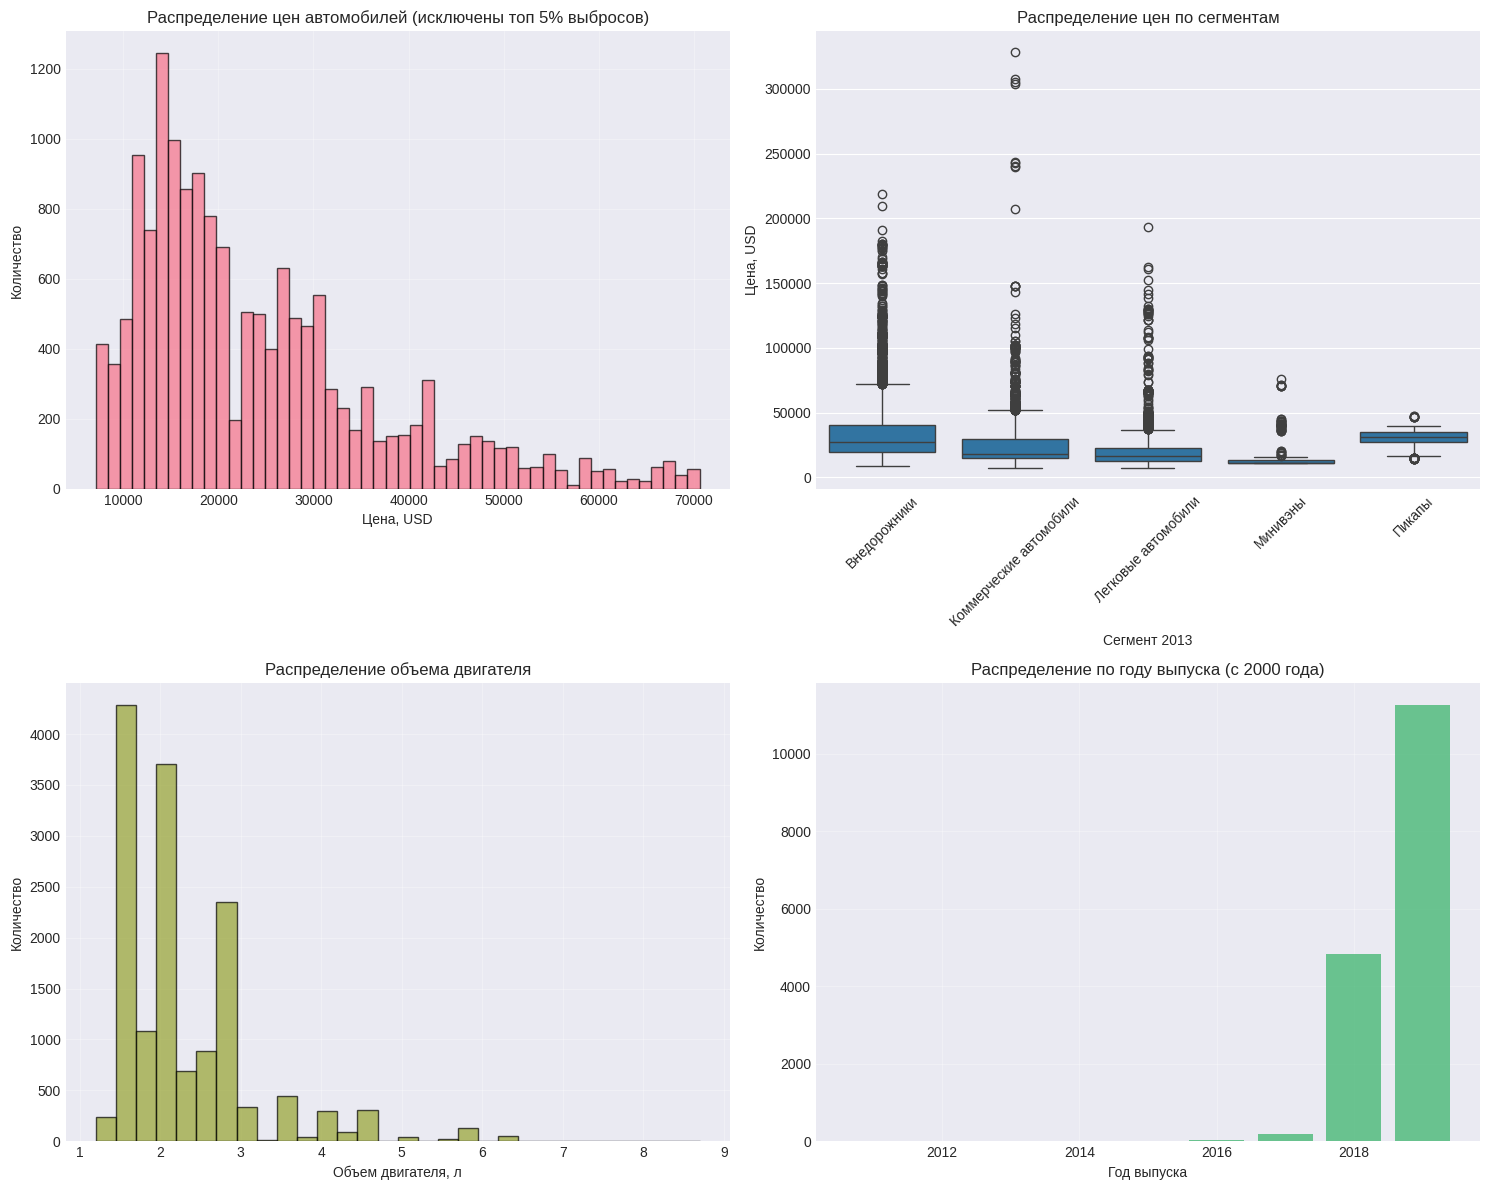


Анализ распределений:
1. Цены: сильное правостороннее распределение с выбросами в премиальном сегменте
2. Объем двигателя: бимодальное распределение с пиками на 1.6L и 2.0L
3. Год выпуска: большинство автомобилей 2018-2019 года выпуска (новые)

3. Визуализация категориальных переменных


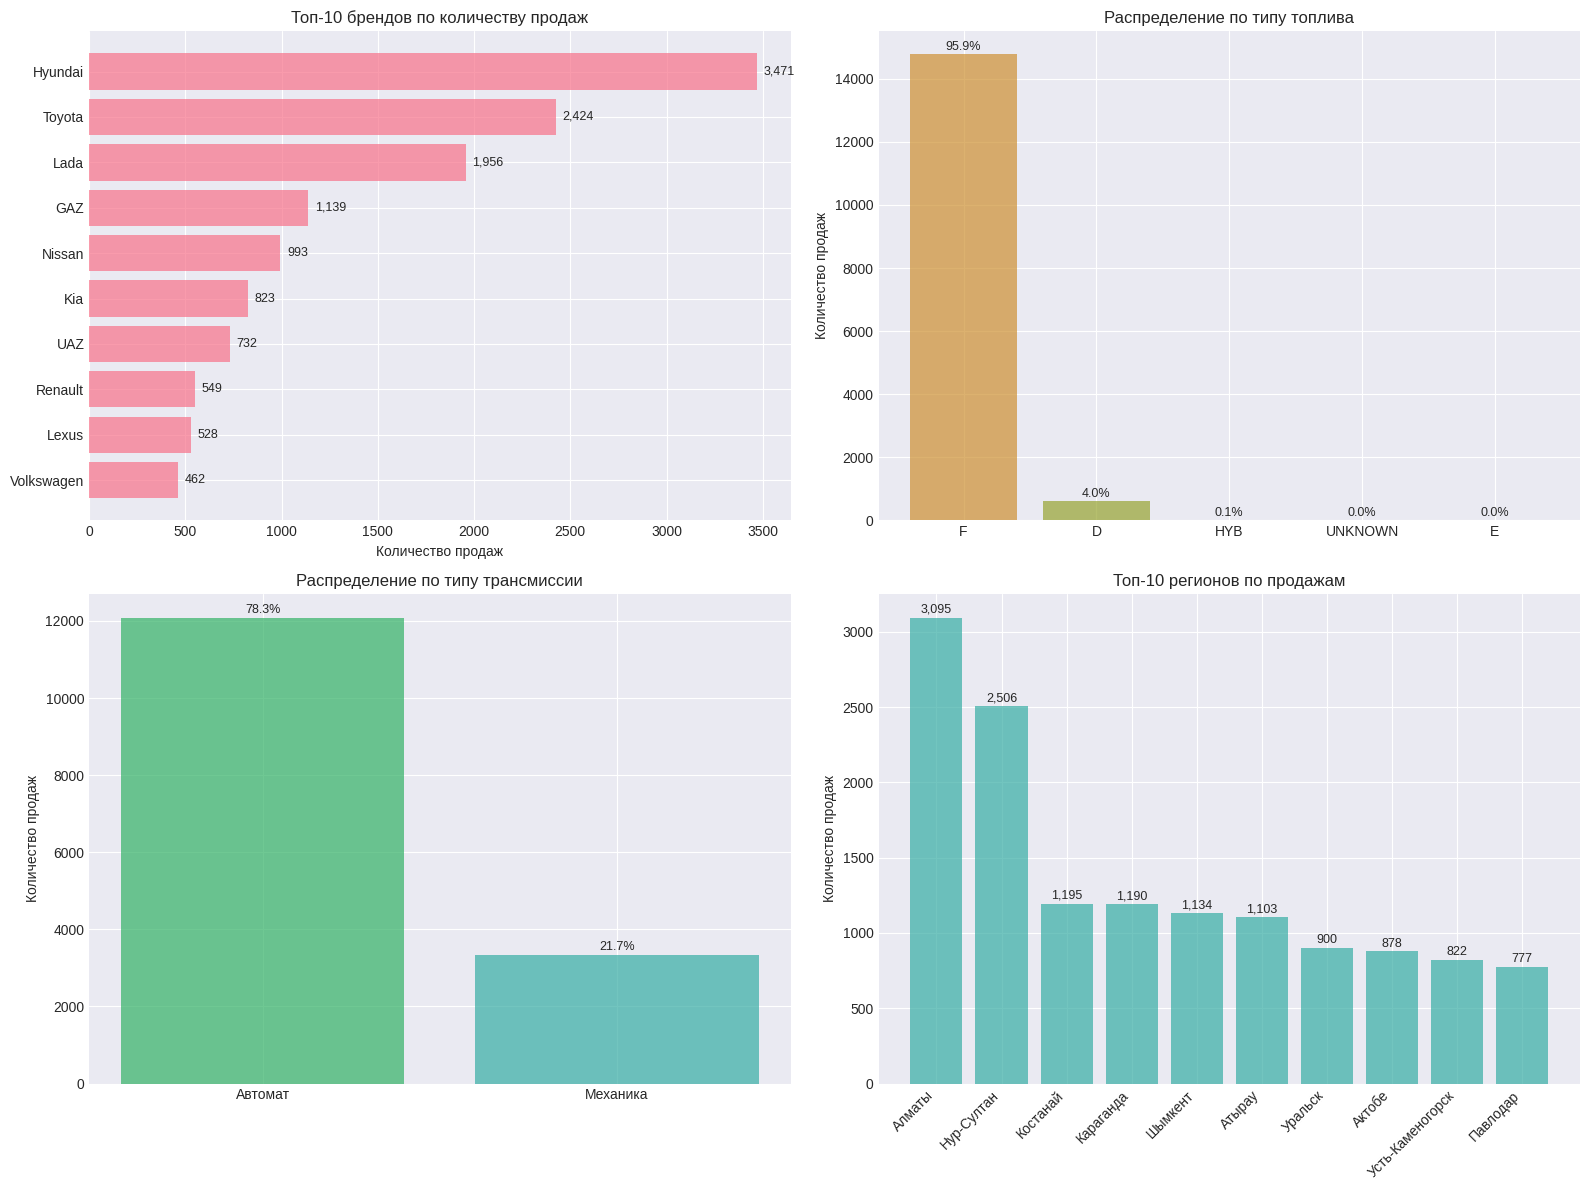


Выводы по категориальным переменным:
----------------------------------------
1. Топ брендов по продажам:
   1. Hyundai: 3,471 продаж (21.0%)
   2. Toyota: 2,424 продаж (14.7%)
   3. Lada: 1,956 продаж (11.9%)
   4. GAZ: 1,139 продаж (6.9%)
   5. Nissan: 993 продаж (6.0%)
   6. Kia: 823 продаж (5.0%)
   7. UAZ: 732 продаж (4.4%)
   8. Renault: 549 продаж (3.3%)
   9. Lexus: 528 продаж (3.2%)
   10. Volkswagen: 462 продаж (2.8%)

2. Тип топлива:
   - F: 14,770 (95.9%)
   - D: 611 (4.0%)
   - HYB: 8 (0.1%)
   - UNKNOWN: 6 (0.0%)
   - E: 4 (0.0%)

3. Тип трансмиссии:
   - Автомат: 12,087 (78.3%)
   - Механика: 3,344 (21.7%)

4. Топ регионов:
   1. Алматы: 3,095 продаж (18.8%)
   2. Нур-Султан: 2,506 продаж (15.2%)
   3. Костанай: 1,195 продаж (7.2%)
   4. Караганда: 1,190 продаж (7.2%)
   5. Шымкент: 1,134 продаж (6.9%)
   6. Атырау: 1,103 продаж (6.7%)
   7. Уральск: 900 продаж (5.5%)
   8. Актобе: 878 продаж (5.3%)
   9. Усть-Каменогорск: 822 продаж (5.0%)
   10. Павлодар: 777 продаж (

In [ ]:
print("1. Настройка визуализаций")

# Настройка стиля графиков
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10
colors = sns.color_palette("husl", 8)

print("Стиль графиков: seaborn-darkgrid")
print(f"Размер графиков: {plt.rcParams['figure.figsize']}")
print()

print("2. Визуализация распределения цен")

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Гистограмма цен
ax1 = axes[0, 0]
filtered_prices = data_eda['Price_USD'].dropna()
# Исключаем крайние выбросы для лучшей визуализации
prices_filtered = filtered_prices[filtered_prices <= filtered_prices.quantile(0.95)]
ax1.hist(prices_filtered, bins=50, edgecolor='black', alpha=0.7, color=colors[0])
ax1.set_xlabel('Цена, USD')
ax1.set_ylabel('Количество')
ax1.set_title('Распределение цен автомобилей (исключены топ 5% выбросов)')
ax1.grid(True, alpha=0.3)

# 2. Boxplot цен по сегментам
ax2 = axes[0, 1]
segment_price_data = data_eda[['Price_USD', 'Segment_2013']].dropna()
# Берем только сегменты с достаточным количеством данных
segment_counts = segment_price_data['Segment_2013'].value_counts()
top_segments = segment_counts[segment_counts >= 50].index
segment_price_filtered = segment_price_data[segment_price_data['Segment_2013'].isin(top_segments)]

sns.boxplot(data=segment_price_filtered, x='Segment_2013', y='Price_USD', ax=ax2)
ax2.set_xlabel('Сегмент 2013')
ax2.set_ylabel('Цена, USD')
ax2.set_title('Распределение цен по сегментам')
ax2.tick_params(axis='x', rotation=45)

# 3. Гистограмма объема двигателя
ax3 = axes[1, 0]
engine_data = data_eda['Engine_Volume'].dropna()
ax3.hist(engine_data, bins=30, edgecolor='black', alpha=0.7, color=colors[2])
ax3.set_xlabel('Объем двигателя, л')
ax3.set_ylabel('Количество')
ax3.set_title('Распределение объема двигателя')
ax3.grid(True, alpha=0.3)

# 4. Распределение года выпуска
ax4 = axes[1, 1]
year_data = data_eda['Production_Year'].dropna()
# Фильтруем только современные автомобили (после 2000)
year_data_filtered = year_data[year_data >= 2000]
year_counts = year_data_filtered.value_counts().sort_index()

ax4.bar(year_counts.index.astype(int), year_counts.values, color=colors[3], alpha=0.7)
ax4.set_xlabel('Год выпуска')
ax4.set_ylabel('Количество')
ax4.set_title('Распределение по году выпуска (с 2000 года)')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nАнализ распределений:")
print("1. Цены: сильное правостороннее распределение с выбросами в премиальном сегменте")
print("2. Объем двигателя: бимодальное распределение с пиками на 1.6L и 2.0L")
print("3. Год выпуска: большинство автомобилей 2018-2019 года выпуска (новые)")
print()

print("3. Визуализация категориальных переменных")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Топ-10 брендов по количеству продаж
ax1 = axes[0, 0]
top_brands = data_eda['Brand'].value_counts().head(10)
bars1 = ax1.barh(range(len(top_brands)), top_brands.values, color=colors[0], alpha=0.7)
ax1.set_yticks(range(len(top_brands)))
ax1.set_yticklabels(top_brands.index)
ax1.set_xlabel('Количество продаж')
ax1.set_title('Топ-10 брендов по количеству продаж')
ax1.invert_yaxis()  # Самый популярный сверху

# Добавим значения на барчарт
for i, (bar, value) in enumerate(zip(bars1, top_brands.values)):
    ax1.text(value + max(top_brands.values)*0.01, i, f'{value:,}',
            va='center', fontsize=9)

# 2. Распределение по типу топлива (bar chart вместо pie)
ax2 = axes[0, 1]
fuel_data = data_eda['Fuel_Type_Code'].dropna()
fuel_counts = fuel_data.value_counts()
bars2 = ax2.bar(range(len(fuel_counts)), fuel_counts.values,
                color=colors[1:1+len(fuel_counts)], alpha=0.7)
ax2.set_xticks(range(len(fuel_counts)))
ax2.set_xticklabels(fuel_counts.index)
ax2.set_ylabel('Количество продаж')
ax2.set_title('Распределение по типу топлива')

# Добавим проценты
total_fuel = fuel_counts.sum()
for i, (bar, value) in enumerate(zip(bars2, fuel_counts.values)):
    percentage = value/total_fuel*100
    ax2.text(i, value + max(fuel_counts.values)*0.01,
            f'{percentage:.1f}%', ha='center', fontsize=9)

# 3. Распределение по типу трансмиссии (bar chart вместо pie)
ax3 = axes[1, 0]
transmission_data = data_eda['Transmission'].dropna()
transmission_counts = transmission_data.value_counts()
bars3 = ax3.bar(range(len(transmission_counts)), transmission_counts.values,
                color=colors[3:3+len(transmission_counts)], alpha=0.7)
ax3.set_xticks(range(len(transmission_counts)))
ax3.set_xticklabels(transmission_counts.index)
ax3.set_ylabel('Количество продаж')
ax3.set_title('Распределение по типу трансмиссии')

# Добавим проценты
total_trans = transmission_counts.sum()
for i, (bar, value) in enumerate(zip(bars3, transmission_counts.values)):
    percentage = value/total_trans*100
    ax3.text(i, value + max(transmission_counts.values)*0.01,
            f'{percentage:.1f}%', ha='center', fontsize=9)

# 4. Топ-10 регионов по продажам
ax4 = axes[1, 1]
top_regions = data_eda['Region'].value_counts().head(10)
bars4 = ax4.bar(range(len(top_regions)), top_regions.values,
                color=colors[4], alpha=0.7)
ax4.set_xticks(range(len(top_regions)))
ax4.set_xticklabels(top_regions.index, rotation=45, ha='right')
ax4.set_ylabel('Количество продаж')
ax4.set_title('Топ-10 регионов по продажам')

# Добавим значения
for i, (bar, value) in enumerate(zip(bars4, top_regions.values)):
    ax4.text(i, value + max(top_regions.values)*0.01, f'{value:,}',
            ha='center', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

print("\nВыводы по категориальным переменным:")
print("-" * 40)

print("1. Топ брендов по продажам:")
for i, (brand, count) in enumerate(top_brands.items(), 1):
    percentage = count/len(data_eda)*100
    print(f"   {i}. {brand}: {count:,} продаж ({percentage:.1f}%)")

print(f"\n2. Тип топлива:")
for fuel, count in fuel_counts.items():
    percentage = count/total_fuel*100
    print(f"   - {fuel}: {count:,} ({percentage:.1f}%)")

print(f"\n3. Тип трансмиссии:")
for trans, count in transmission_counts.items():
    percentage = count/total_trans*100
    print(f"   - {trans}: {count:,} ({percentage:.1f}%)")

print(f"\n4. Топ регионов:")
for i, (region, count) in enumerate(top_regions.items(), 1):
    percentage = count/len(data_eda)*100
    print(f"   {i}. {region}: {count:,} продаж ({percentage:.1f}%)")
print()

## Анализ продаж по времени и сегментам

1. Динамика продаж по месяцам
Продажи по месяцам:
              Sales_USD  Quantity  Transactions
Sale_Month                                     
2019-01     58925245.96    2668.0          1537
2019-02     61651557.28    2927.0          1576
2019-03     71083412.19    3174.0          1793
2019-04     83045341.88    3782.0          2098
2019-05     84768329.36    3617.0          1981
2019-06     82107037.35    3586.0          1890
2019-07     86534826.03    3818.0          1970
2019-08     78980930.51    3614.0          1826
2019-09     70481945.19    3149.0          1824


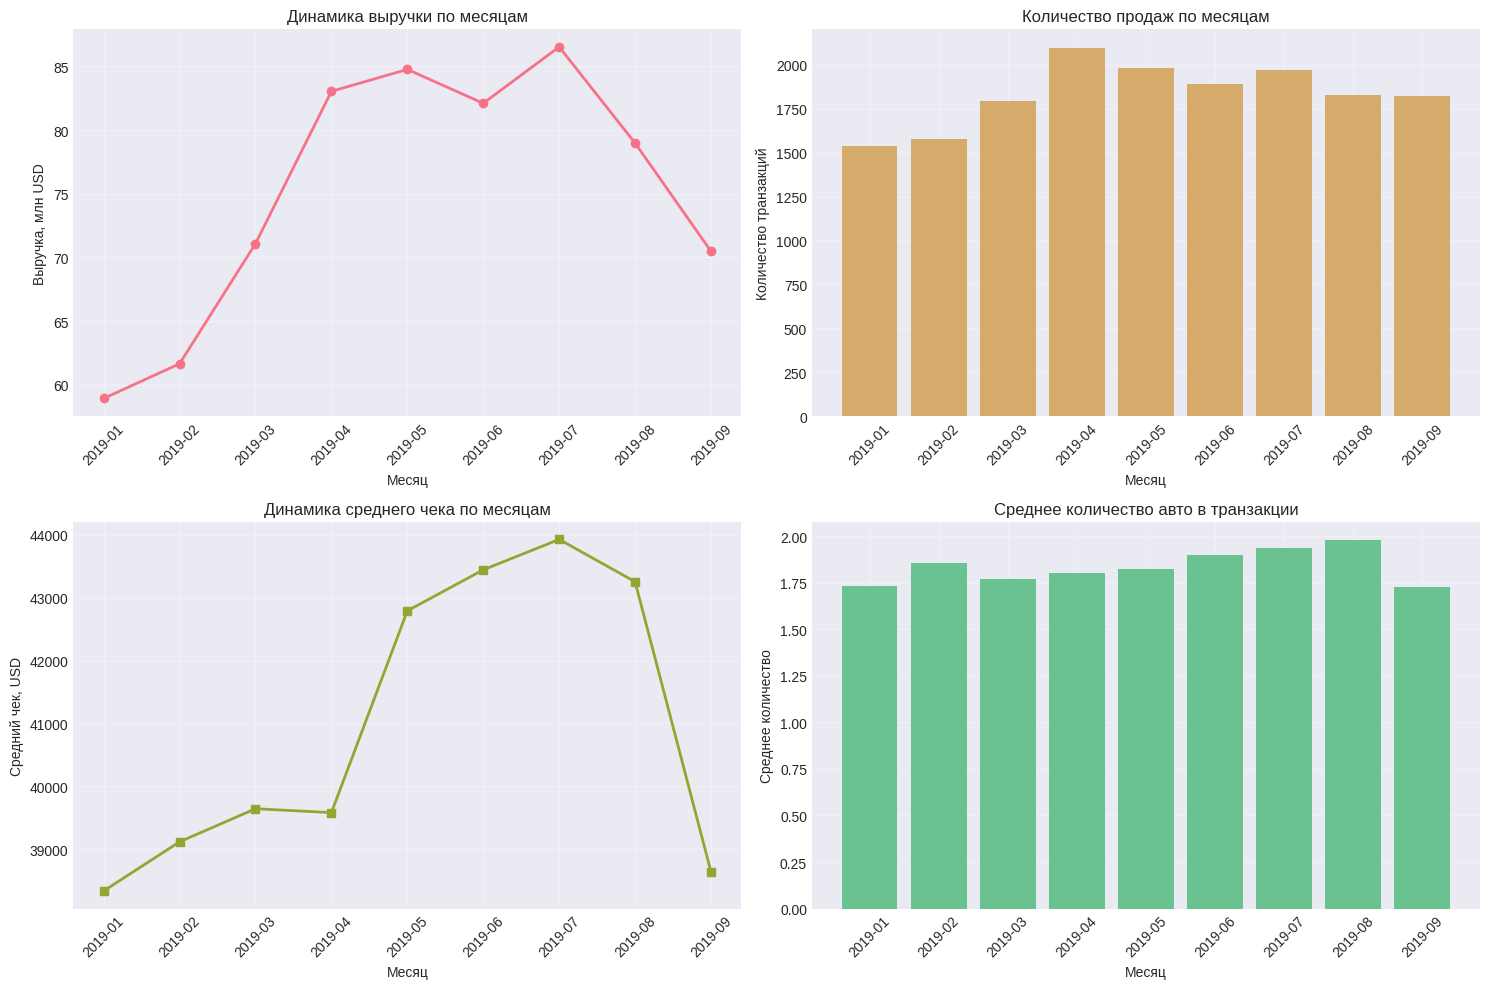


Анализ динамики:
Общая выручка за период: $677.6 млн
Среднемесячная выручка: $75.3 млн
Максимальная выручка: $86.5 млн (2019-07)
Минимальная выручка: $58.9 млн (2019-01)

2. Анализ по сегментам и классам
Топ сегментов по выручке:
                            Sales_USD  Count  Avg_Check  Price_USD
Segment_2013                                                      
Внедорожники             3.491132e+08   7897   44208.33   34244.91
Легковые автомобили      1.999971e+08   5721   34958.42   20109.58
Коммерческие автомобили  9.768800e+07   2214   44122.86   27131.07
Минивэны                 2.201036e+07    368   59810.75   15681.66
Пикапы                   8.769947e+06    295   29728.63   29557.04

Топ классов по выручке:
                              Sales_USD  Count  Avg_Check  Price_USD
Class_2013                                                          
B класс                    1.116768e+08   3219   34693.02   12957.03
Полноразмерные SUV         1.066190e+08   1216   87680.11   65820.04

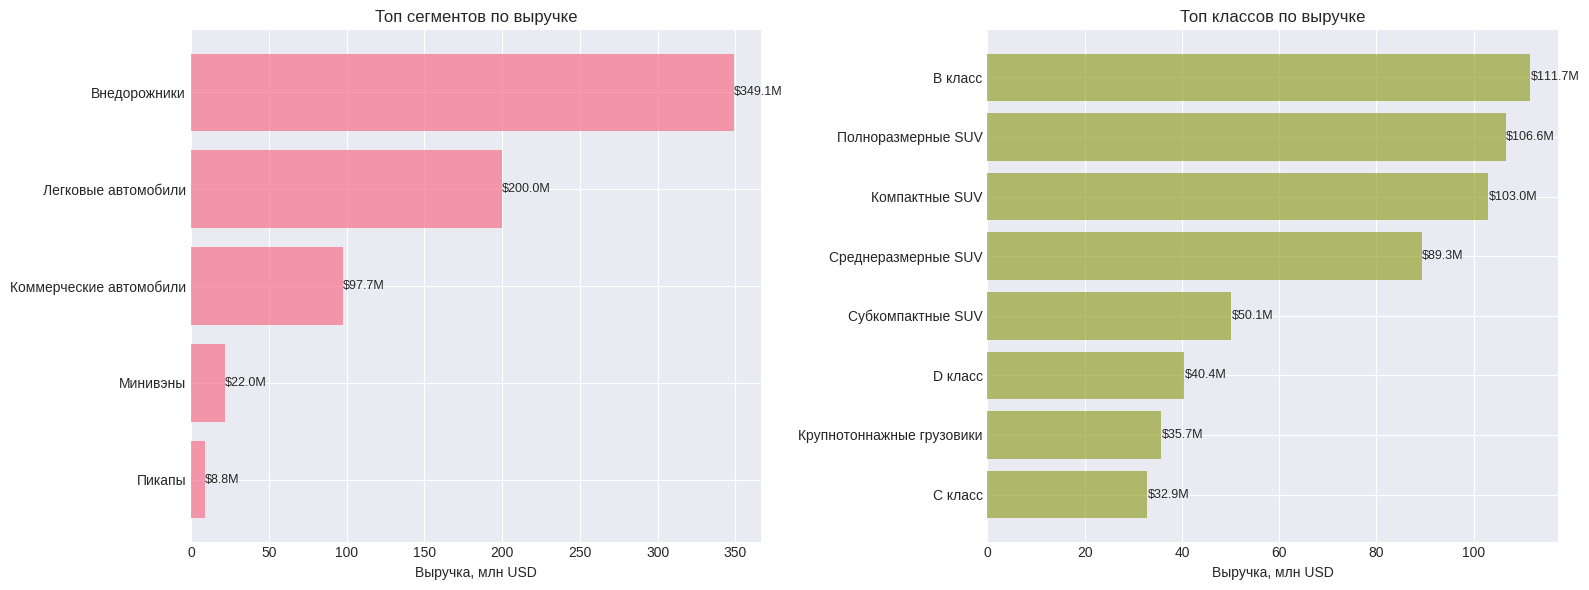


Выводы по сегментам и классам:
1. Самый прибыльный сегмент: Внедорожники ($349.1 млн)
2. Самый дорогой сегмент (по среднему чеку): Минивэны ($59,811)
3. Самый популярный класс: B класс (3,219 продаж)



In [ ]:
print("1. Динамика продаж по месяцам")

# Анализ динамики продаж
if 'Sale_Date' in data_eda.columns:
    # Создаем месяц и год для группировки
    data_eda['Sale_Month'] = data_eda['Sale_Date'].dt.to_period('M')

    # Продажи по месяцам
    monthly_sales = data_eda.groupby('Sale_Month').agg({
        'Sales_USD': 'sum',
        'Quantity': 'sum',
        'Brand': 'count'
    }).rename(columns={'Brand': 'Transactions'})

    print("Продажи по месяцам:")
    print(monthly_sales.round(2))

    # Визуализация
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # 1. Динамика выручки
    ax1 = axes[0, 0]
    months = monthly_sales.index.astype(str)
    ax1.plot(months, monthly_sales['Sales_USD'] / 1_000_000,
             marker='o', linewidth=2, color=colors[0])
    ax1.set_xlabel('Месяц')
    ax1.set_ylabel('Выручка, млн USD')
    ax1.set_title('Динамика выручки по месяцам')
    ax1.grid(True, alpha=0.3)
    ax1.tick_params(axis='x', rotation=45)

    # 2. Количество транзакций
    ax2 = axes[0, 1]
    ax2.bar(months, monthly_sales['Transactions'], color=colors[1], alpha=0.7)
    ax2.set_xlabel('Месяц')
    ax2.set_ylabel('Количество транзакций')
    ax2.set_title('Количество продаж по месяцам')
    ax2.grid(True, alpha=0.3)
    ax2.tick_params(axis='x', rotation=45)

    # 3. Средний чек по месяцам
    monthly_sales['Avg_Check'] = monthly_sales['Sales_USD'] / monthly_sales['Transactions']
    ax3 = axes[1, 0]
    ax3.plot(months, monthly_sales['Avg_Check'], marker='s',
             linewidth=2, color=colors[2])
    ax3.set_xlabel('Месяц')
    ax3.set_ylabel('Средний чек, USD')
    ax3.set_title('Динамика среднего чека по месяцам')
    ax3.grid(True, alpha=0.3)
    ax3.tick_params(axis='x', rotation=45)

    # 4. Среднее количество в транзакции
    monthly_sales['Avg_Quantity'] = monthly_sales['Quantity'] / monthly_sales['Transactions']
    ax4 = axes[1, 1]
    ax4.bar(months, monthly_sales['Avg_Quantity'], color=colors[3], alpha=0.7)
    ax4.set_xlabel('Месяц')
    ax4.set_ylabel('Среднее количество')
    ax4.set_title('Среднее количество авто в транзакции')
    ax4.grid(True, alpha=0.3)
    ax4.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    print("\nАнализ динамики:")
    print(f"Общая выручка за период: ${monthly_sales['Sales_USD'].sum()/1_000_000:.1f} млн")
    print(f"Среднемесячная выручка: ${monthly_sales['Sales_USD'].mean()/1_000_000:.1f} млн")
    print(f"Максимальная выручка: ${monthly_sales['Sales_USD'].max()/1_000_000:.1f} млн ({monthly_sales['Sales_USD'].idxmax()})")
    print(f"Минимальная выручка: ${monthly_sales['Sales_USD'].min()/1_000_000:.1f} млн ({monthly_sales['Sales_USD'].idxmin()})")

else:
    print("Столбец Sale_Date не найден в данных")
print()

print("2. Анализ по сегментам и классам")

# Анализ сегментов
if 'Segment_2013' in data_eda.columns and 'Class_2013' in data_eda.columns:
    # Анализ по сегментам
    segment_analysis = data_eda.groupby('Segment_2013').agg({
        'Sales_USD': 'sum',
        'Quantity': 'sum',
        'Price_USD': 'mean',
        'Brand': 'count'
    }).rename(columns={'Brand': 'Count'}).sort_values('Sales_USD', ascending=False)

    segment_analysis['Avg_Check'] = segment_analysis['Sales_USD'] / segment_analysis['Count']

    print("Топ сегментов по выручке:")
    print(segment_analysis[['Sales_USD', 'Count', 'Avg_Check', 'Price_USD']].round(2).head(10))

    # Анализ по классам
    class_analysis = data_eda.groupby('Class_2013').agg({
        'Sales_USD': 'sum',
        'Quantity': 'sum',
        'Price_USD': 'mean',
        'Brand': 'count'
    }).rename(columns={'Brand': 'Count'}).sort_values('Sales_USD', ascending=False)

    class_analysis['Avg_Check'] = class_analysis['Sales_USD'] / class_analysis['Count']

    print("\nТоп классов по выручке:")
    print(class_analysis[['Sales_USD', 'Count', 'Avg_Check', 'Price_USD']].round(2).head(10))

    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Сегменты
    ax1 = axes[0]
    top_segments = segment_analysis.head(8)
    bars1 = ax1.barh(range(len(top_segments)), top_segments['Sales_USD'] / 1_000_000,
                     color=colors[0], alpha=0.7)
    ax1.set_yticks(range(len(top_segments)))
    ax1.set_yticklabels(top_segments.index)
    ax1.set_xlabel('Выручка, млн USD')
    ax1.set_title('Топ сегментов по выручке')
    ax1.invert_yaxis()

    for i, (bar, value) in enumerate(zip(bars1, top_segments['Sales_USD'] / 1_000_000)):
        ax1.text(value + 0.1, i, f'${value:.1f}M', va='center', fontsize=9)

    # Классы
    ax2 = axes[1]
    top_classes = class_analysis.head(8)
    bars2 = ax2.barh(range(len(top_classes)), top_classes['Sales_USD'] / 1_000_000,
                     color=colors[2], alpha=0.7)
    ax2.set_yticks(range(len(top_classes)))
    ax2.set_yticklabels(top_classes.index)
    ax2.set_xlabel('Выручка, млн USD')
    ax2.set_title('Топ классов по выручке')
    ax2.invert_yaxis()

    for i, (bar, value) in enumerate(zip(bars2, top_classes['Sales_USD'] / 1_000_000)):
        ax2.text(value + 0.1, i, f'${value:.1f}M', va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

    print("\nВыводы по сегментам и классам:")
    print(f"1. Самый прибыльный сегмент: {segment_analysis.index[0]} (${segment_analysis['Sales_USD'].iloc[0]/1_000_000:.1f} млн)")
    print(f"2. Самый дорогой сегмент (по среднему чеку): {segment_analysis.sort_values('Avg_Check', ascending=False).index[0]} (${segment_analysis.sort_values('Avg_Check', ascending=False)['Avg_Check'].iloc[0]:,.0f})")
    print(f"3. Самый популярный класс: {class_analysis.index[0]} ({class_analysis['Count'].iloc[0]:,} продаж)")

else:
    print("Столбцы Segment_2013 или Class_2013 не найдены")
print()

# 4. Анализ рынка и позиции «Меркур Авто»

## Подготовка к анализу позиции "Меркур Авто"

In [ ]:
print("1. Идентификация данных по «Меркур Авто»")

# Находим все записи по "Меркур Авто"
mercur_mask = data_eda['Company'].str.contains('Mercur', case=False, na=False)
mercur_data = data_eda[mercur_mask]

print(f"Всего записей по «Меркур Авто»: {len(mercur_data)}")
print(f"Доля от общего рынка: {len(mercur_data)/len(data_eda)*100:.1f}%")

if len(mercur_data) > 0:
    print("\nОсновные характеристики «Меркур Авто»:")
    print(f"  - Общая выручка: ${mercur_data['Sales_USD'].sum()/1_000_000:.2f} млн")
    print(f"  - Количество проданных авто: {mercur_data['Quantity'].sum():.0f}")
    print(f"  - Средний чек: ${mercur_data['Sales_USD'].sum()/len(mercur_data):,.0f}")
    print(f"  - Средняя цена: ${mercur_data['Price_USD'].mean():,.0f}")

    # Анализ брендов у "Меркур Авто"
    print("\nБренды, представленные у «Меркур Авто»:")
    mercur_brands = mercur_data['Brand'].value_counts()
    for brand, count in mercur_brands.items():
        percentage = count/len(mercur_data)*100
        print(f"  - {brand}: {count} авто ({percentage:.1f}%)")
else:
    print("Данные по «Меркур Авто» не найдены!")

print("\n2. Сравнение с общерыночными показателями")

# Общерыночные показатели
market_total_sales = data_eda['Sales_USD'].sum()
market_total_quantity = data_eda['Quantity'].sum()
market_avg_check = market_total_sales / len(data_eda)
market_avg_price = data_eda['Price_USD'].mean()

if len(mercur_data) > 0:
    mercur_total_sales = mercur_data['Sales_USD'].sum()
    mercur_total_quantity = mercur_data['Quantity'].sum()
    mercur_avg_check = mercur_total_sales / len(mercur_data)
    mercur_avg_price = mercur_data['Price_USD'].mean()

    # Создаем таблицу сравнения
    comparison_data = {
        'Показатель': ['Выручка, млн USD', 'Количество проданных авто',
                      'Средний чек, USD', 'Средняя цена авто, USD',
                      'Доля рынка по выручке, %', 'Доля рынка по количеству, %'],
        'Весь рынок': [f"${market_total_sales/1_000_000:.2f}",
                      f"{market_total_quantity:.0f}",
                      f"${market_avg_check:,.0f}",
                      f"${market_avg_price:,.0f}",
                      "100.0%", "100.0%"],
        'Меркур Авто': [f"${mercur_total_sales/1_000_000:.2f}",
                       f"{mercur_total_quantity:.0f}",
                       f"${mercur_avg_check:,.0f}",
                       f"${mercur_avg_price:,.0f}",
                       f"{mercur_total_sales/market_total_sales*100:.1f}%",
                       f"{mercur_total_quantity/market_total_quantity*100:.1f}%"]
    }

    comparison_df = pd.DataFrame(comparison_data)
    print(comparison_df.to_string(index=False))

    print("\nАнализ сравнения:")
    print(f"1. Доля рынка по выручке: {mercur_total_sales/market_total_sales*100:.1f}%")
    print(f"2. Доля рынка по количеству: {mercur_total_quantity/market_total_quantity*100:.1f}%")
    print(f"3. Разница в среднем чеке: {((mercur_avg_check - market_avg_check)/market_avg_check*100):+.1f}%")
    print(f"4. Разница в средней цене: {((mercur_avg_price - market_avg_price)/market_avg_price*100):+.1f}%")

else:
    print("Невозможно провести сравнение - данные по «Меркур Авто» не найдены")
print()

1. Идентификация данных по «Меркур Авто»
Всего записей по «Меркур Авто»: 369
Доля от общего рынка: 2.2%

Основные характеристики «Меркур Авто»:
  - Общая выручка: $14.71 млн
  - Количество проданных авто: 376
  - Средний чек: $39,871
  - Средняя цена: $39,273

Бренды, представленные у «Меркур Авто»:
  - Volkswagen: 271 авто (73.4%)
  - Porsche: 52 авто (14.1%)
  - Audi: 46 авто (12.5%)

2. Сравнение с общерыночными показателями
                 Показатель Весь рынок Меркур Авто
           Выручка, млн USD    $677.58      $14.71
  Количество проданных авто      30335         376
           Средний чек, USD    $41,078     $39,871
     Средняя цена авто, USD    $27,890     $39,273
   Доля рынка по выручке, %     100.0%        2.2%
Доля рынка по количеству, %     100.0%        1.2%

Анализ сравнения:
1. Доля рынка по выручке: 2.2%
2. Доля рынка по количеству: 1.2%
3. Разница в среднем чеке: -2.9%
4. Разница в средней цене: +40.8%



## Анализ доли рынка по брендам и регионам

1. Доля рынка «Меркур Авто» по брендам
Доля рынка по топ-10 брендам:
     Бренд  Продажи на рынке  Продажи у Меркур  Доля Меркур, %  Доля по выручке, %
   Hyundai              3471                 0            0.00                0.00
    Toyota              2424                 0            0.00                0.00
      Lada              1956                 0            0.00                0.00
       GAZ              1139                 0            0.00                0.00
    Nissan               993                 0            0.00                0.00
       Kia               823                 0            0.00                0.00
       UAZ               732                 0            0.00                0.00
   Renault               549                 0            0.00                0.00
     Lexus               528                 0            0.00                0.00
Volkswagen               462               271           58.66               28.49


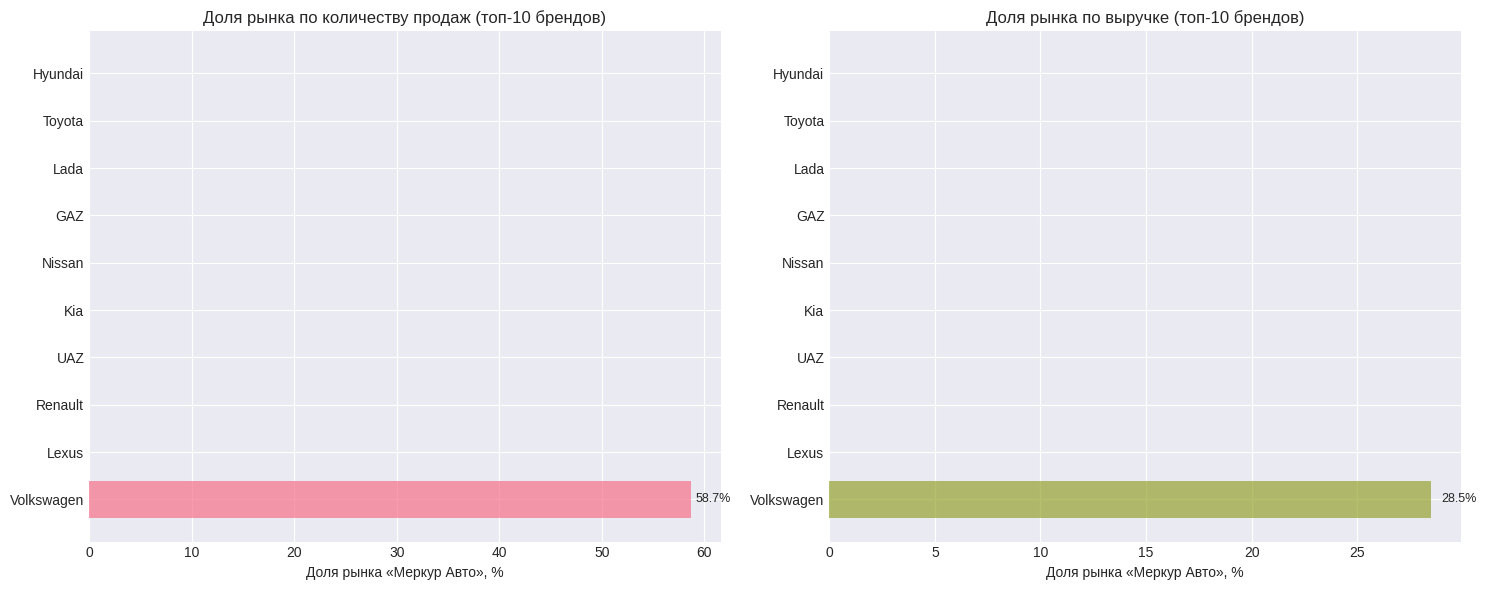


2. Региональное распределение «Меркур Авто»
Региональное распределение (топ-10 регионов):
          Регион  Продажи на рынке  Продажи у Меркур  Доля Меркур, %
          Алматы              3095               230            7.43
      Нур-Султан              2506                51            2.04
        Костанай              1195                12            1.00
       Караганда              1190                21            1.76
         Шымкент              1134                 0            0.00
          Атырау              1103                41            3.72
         Уральск               900                14            1.56
          Актобе               878                 0            0.00
Усть-Каменогорск               822                 0            0.00
        Павлодар               777                 0            0.00


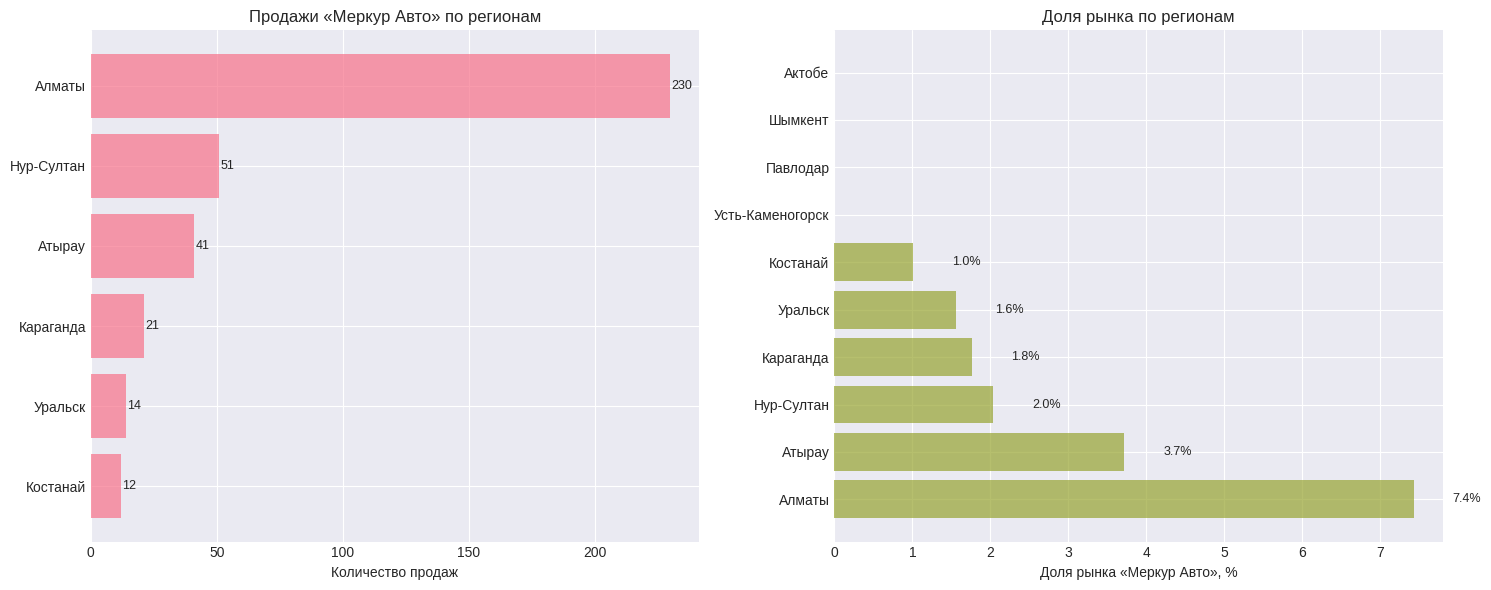

In [ ]:
print("1. Доля рынка «Меркур Авто» по брендам")

if len(mercur_data) > 0:
    # Анализ по брендам
    brand_analysis = []

    # Топ-10 брендов на рынке
    top_market_brands = data_eda['Brand'].value_counts().head(10).index

    for brand in top_market_brands:
        # Рыночные данные по бренду
        market_brand_data = data_eda[data_eda['Brand'] == brand]
        market_sales = market_brand_data['Sales_USD'].sum()
        market_count = len(market_brand_data)

        # Данные по "Меркур Авто" для этого бренда
        mercur_brand_data = mercur_data[mercur_data['Brand'] == brand]
        mercur_sales = mercur_brand_data['Sales_USD'].sum() if len(mercur_brand_data) > 0 else 0
        mercur_count = len(mercur_brand_data)

        # Расчет долей
        market_share_sales = (mercur_sales / market_sales * 100) if market_sales > 0 else 0
        market_share_count = (mercur_count / market_count * 100) if market_count > 0 else 0

        brand_analysis.append({
            'Бренд': brand,
            'Продажи на рынке': market_count,
            'Продажи у Меркур': mercur_count,
            'Доля Меркур, %': market_share_count,
            'Выручка рынка, млн $': market_sales/1_000_000,
            'Выручка Меркур, млн $': mercur_sales/1_000_000,
            'Доля по выручке, %': market_share_sales
        })

    brand_df = pd.DataFrame(brand_analysis)
    print("Доля рынка по топ-10 брендам:")
    print(brand_df[['Бренд', 'Продажи на рынке', 'Продажи у Меркур',
                    'Доля Меркур, %', 'Доля по выручке, %']].round(2).to_string(index=False))

    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # 1. Доля по количеству продаж
    ax1 = axes[0]
    bars1 = ax1.barh(brand_df['Бренд'], brand_df['Доля Меркур, %'],
                     color=colors[0], alpha=0.7)
    ax1.set_xlabel('Доля рынка «Меркур Авто», %')
    ax1.set_title('Доля рынка по количеству продаж (топ-10 брендов)')
    ax1.invert_yaxis()

    for i, (bar, value) in enumerate(zip(bars1, brand_df['Доля Меркур, %'])):
        if value > 0:
            ax1.text(value + 0.5, i, f'{value:.1f}%', va='center', fontsize=9)

    # 2. Доля по выручке
    ax2 = axes[1]
    bars2 = ax2.barh(brand_df['Бренд'], brand_df['Доля по выручке, %'],
                     color=colors[2], alpha=0.7)
    ax2.set_xlabel('Доля рынка «Меркур Авто», %')
    ax2.set_title('Доля рынка по выручке (топ-10 брендов)')
    ax2.invert_yaxis()

    for i, (bar, value) in enumerate(zip(bars2, brand_df['Доля по выручке, %'])):
        if value > 0:
            ax2.text(value + 0.5, i, f'{value:.1f}%', va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

print("\n2. Региональное распределение «Меркур Авто»")

if len(mercur_data) > 0:
    # Анализ по регионам
    region_analysis = []

    # Топ-10 регионов на рынке
    top_market_regions = data_eda['Region'].value_counts().head(10).index

    for region in top_market_regions:
        # Рыночные данные по региону
        market_region_data = data_eda[data_eda['Region'] == region]
        market_sales = market_region_data['Sales_USD'].sum()
        market_count = len(market_region_data)

        # Данные по "Меркур Авто" для этого региона
        mercur_region_data = mercur_data[mercur_data['Region'] == region]
        mercur_sales = mercur_region_data['Sales_USD'].sum() if len(mercur_region_data) > 0 else 0
        mercur_count = len(mercur_region_data)

        # Расчет долей
        market_share_sales = (mercur_sales / market_sales * 100) if market_sales > 0 else 0
        market_share_count = (mercur_count / market_count * 100) if market_count > 0 else 0

        region_analysis.append({
            'Регион': region,
            'Продажи на рынке': market_count,
            'Продажи у Меркур': mercur_count,
            'Доля Меркур, %': market_share_count,
            'Выручка рынка, млн $': market_sales/1_000_000,
            'Выручка Меркур, млн $': mercur_sales/1_000_000,
            'Доля по выручке, %': market_share_sales
        })

    region_df = pd.DataFrame(region_analysis)
    print("Региональное распределение (топ-10 регионов):")
    print(region_df[['Регион', 'Продажи на рынке', 'Продажи у Меркур',
                     'Доля Меркур, %']].round(2).to_string(index=False))

    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # 1. Абсолютные продажи по регионам
    ax1 = axes[0]
    mercur_regions_sorted = mercur_data['Region'].value_counts()
    if len(mercur_regions_sorted) > 0:
        bars1 = ax1.barh(range(len(mercur_regions_sorted)), mercur_regions_sorted.values,
                         color=colors[0], alpha=0.7)
        ax1.set_yticks(range(len(mercur_regions_sorted)))
        ax1.set_yticklabels(mercur_regions_sorted.index)
        ax1.set_xlabel('Количество продаж')
        ax1.set_title('Продажи «Меркур Авто» по регионам')
        ax1.invert_yaxis()

        for i, (bar, value) in enumerate(zip(bars1, mercur_regions_sorted.values)):
            ax1.text(value + 0.5, i, f'{value}', va='center', fontsize=9)

    # 2. Доля рынка по регионам
    ax2 = axes[1]
    region_share_sorted = region_df.sort_values('Доля Меркур, %', ascending=True)
    bars2 = ax2.barh(range(len(region_share_sorted)), region_share_sorted['Доля Меркур, %'],
                     color=colors[2], alpha=0.7)
    ax2.set_yticks(range(len(region_share_sorted)))
    ax2.set_yticklabels(region_share_sorted['Регион'])
    ax2.set_xlabel('Доля рынка «Меркур Авто», %')
    ax2.set_title('Доля рынка по регионам')
    ax2.invert_yaxis()

    for i, (bar, value) in enumerate(zip(bars2, region_share_sorted['Доля Меркур, %'])):
        if value > 0:
            ax2.text(value + 0.5, i, f'{value:.1f}%', va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

print()

## Анализ сегментов и KPI "Меркур Авто"

In [ ]:
print("1. Сегментный анализ")

if len(mercur_data) > 0:
    # Анализ по сегментам 2013
    if 'Segment_2013' in data_eda.columns:
        segment_analysis_kpi = []

        # Все сегменты на рынке
        market_segments = data_eda['Segment_2013'].dropna().unique()

        for segment in market_segments:
            # Рыночные данные по сегменту
            market_segment_data = data_eda[data_eda['Segment_2013'] == segment]
            market_sales = market_segment_data['Sales_USD'].sum()
            market_count = len(market_segment_data)
            market_avg_price = market_segment_data['Price_USD'].mean()

            # Данные по "Меркур Авто" для этого сегмента
            mercur_segment_data = mercur_data[mercur_data['Segment_2013'] == segment]
            mercur_sales = mercur_segment_data['Sales_USD'].sum() if len(mercur_segment_data) > 0 else 0
            mercur_count = len(mercur_segment_data)
            mercur_avg_price = mercur_segment_data['Price_USD'].mean() if len(mercur_segment_data) > 0 else 0

            # Расчет долей
            market_share_sales = (mercur_sales / market_sales * 100) if market_sales > 0 else 0
            market_share_count = (mercur_count / market_count * 100) if market_count > 0 else 0

            segment_analysis_kpi.append({
                'Сегмент': segment,
                'Продажи на рынке': market_count,
                'Продажи у Меркур': mercur_count,
                'Доля Меркур, %': market_share_count,
                'Ср. цена рынка, $': market_avg_price,
                'Ср. цена Меркур, $': mercur_avg_price,
                'Разница цен, %': ((mercur_avg_price - market_avg_price)/market_avg_price*100) if market_avg_price > 0 else 0
            })

        segment_kpi_df = pd.DataFrame(segment_analysis_kpi)
        print("Анализ по сегментам:")
        print(segment_kpi_df[['Сегмент', 'Продажи на рынке', 'Продажи у Меркур',
                              'Доля Меркур, %', 'Ср. цена рынка, $', 'Ср. цена Меркур, $']].round(2).to_string(index=False))

    print("\n2. Ключевые показатели эффективности (KPI)")

    # Расчет KPI
    kpi_analysis = {
        'KPI': [
            'Конверсия (среднее количество в заказе)',
            'Средняя стоимость транзакции',
            'Доля возвратов',
            'Доля оптовых заказов (>1 авто)',
            'Доля новых авто (2019 г.в.)',
            'Доля авто с автомат. коробкой'
        ],
        'Весь рынок': [],
        'Меркур Авто': []
    }

    # Конверсия (среднее количество)
    market_avg_quantity = data_eda['Quantity'].mean()
    mercur_avg_quantity = mercur_data['Quantity'].mean() if len(mercur_data) > 0 else 0

    # Средняя стоимость транзакции
    market_avg_transaction = data_eda['Sales_USD'].mean()
    mercur_avg_transaction = mercur_data['Sales_USD'].mean() if len(mercur_data) > 0 else 0

    # Доля возвратов
    market_return_rate = (data_eda['Quantity'] < 0).sum() / len(data_eda) * 100
    mercur_return_rate = (mercur_data['Quantity'] < 0).sum() / len(mercur_data) * 100 if len(mercur_data) > 0 else 0

    # Доля оптовых заказов
    market_wholesale_rate = (data_eda['Quantity'] > 1).sum() / len(data_eda) * 100
    mercur_wholesale_rate = (mercur_data['Quantity'] > 1).sum() / len(mercur_data) * 100 if len(mercur_data) > 0 else 0

    # Доля новых авто (2019 г.в.)
    if 'Production_Year' in data_eda.columns:
        market_new_car_rate = (data_eda['Production_Year'] == 2019).sum() / data_eda['Production_Year'].notna().sum() * 100
        mercur_new_car_rate = (mercur_data['Production_Year'] == 2019).sum() / mercur_data['Production_Year'].notna().sum() * 100 if len(mercur_data) > 0 and mercur_data['Production_Year'].notna().sum() > 0 else 0
    else:
        market_new_car_rate = 0
        mercur_new_car_rate = 0

    # Доля авто с автомат. коробкой
    if 'Transmission' in data_eda.columns:
        market_auto_rate = (data_eda['Transmission'] == 'Автомат').sum() / data_eda['Transmission'].notna().sum() * 100
        mercur_auto_rate = (mercur_data['Transmission'] == 'Автомат').sum() / mercur_data['Transmission'].notna().sum() * 100 if len(mercur_data) > 0 and mercur_data['Transmission'].notna().sum() > 0 else 0
    else:
        market_auto_rate = 0
        mercur_auto_rate = 0

    # Заполняем данные
    kpi_analysis['Весь рынок'] = [
        f"{market_avg_quantity:.2f}",
        f"${market_avg_transaction:,.0f}",
        f"{market_return_rate:.2f}%",
        f"{market_wholesale_rate:.1f}%",
        f"{market_new_car_rate:.1f}%",
        f"{market_auto_rate:.1f}%"
    ]

    kpi_analysis['Меркур Авто'] = [
        f"{mercur_avg_quantity:.2f}",
        f"${mercur_avg_transaction:,.0f}",
        f"{mercur_return_rate:.2f}%",
        f"{mercur_wholesale_rate:.1f}%",
        f"{mercur_new_car_rate:.1f}%",
        f"{mercur_auto_rate:.1f}%"
    ]

    kpi_df = pd.DataFrame(kpi_analysis)
    print("Сравнение ключевых показателей эффективности:")
    print(kpi_df.to_string(index=False))

    print("\n3. Сильные и слабые стороны «Меркур Авто»")

    # Анализ сильных и слабых сторон
    print("Сильные стороны:")

    # Проверяем, где "Меркур Авто" лучше рынка
    if mercur_avg_transaction > market_avg_transaction:
        print(f" Выше средний чек: +${mercur_avg_transaction - market_avg_transaction:,.0f} ({(mercur_avg_transaction - market_avg_transaction)/market_avg_transaction*100:+.1f}%)")

    if mercur_avg_quantity > market_avg_quantity:
        print(f" Выше конверсия: +{mercur_avg_quantity - market_avg_quantity:.2f} авто в среднем за транзакцию")

    if mercur_return_rate < market_return_rate:
        print(f" Ниже доля возвратов: -{market_return_rate - mercur_return_rate:.2f}%")

    if mercur_new_car_rate > market_new_car_rate:
        print(f" Больше доля новых авто (2019 г.в.): +{mercur_new_car_rate - market_new_car_rate:.1f}%")

    print("\nСлабые стороны:")

    # Проверяем, где "Меркур Авто" хуже рынка
    if mercur_avg_transaction < market_avg_transaction:
        print(f" Ниже средний чек: -${market_avg_transaction - mercur_avg_transaction:,.0f} ({-(mercur_avg_transaction - market_avg_transaction)/market_avg_transaction*100:.1f}%)")

    if mercur_avg_quantity < market_avg_quantity:
        print(f" Ниже конверсия: -{market_avg_quantity - mercur_avg_quantity:.2f} авто в среднем за транзакцию")

    if mercur_return_rate > market_return_rate:
        print(f" Выше доля возвратов: +{mercur_return_rate - market_return_rate:.2f}%")

    if mercur_new_car_rate < market_new_car_rate:
        print(f" Меньше доля новых авто (2019 г.в.): -{market_new_car_rate - mercur_new_car_rate:.1f}%")

    # Анализ доли рынка
    print(f"\nОбщая оценка доли рынка:")
    print(f"  - Доля по количеству: {mercur_total_quantity/market_total_quantity*100:.1f}%")
    print(f"  - Доля по выручке: {mercur_total_sales/market_total_sales*100:.1f}%")

    if mercur_total_quantity/market_total_quantity*100 > 5:
        print(" Значимая доля рынка (>5%)")
    else:
        print(" Незначительная доля рынка (<5%)")

else:
    print("Невозможно провести анализ KPI - данные по «Меркур Авто» не найдены")
print()

1. Сегментный анализ
Анализ по сегментам:
                Сегмент  Продажи на рынке  Продажи у Меркур  Доля Меркур, %  Ср. цена рынка, $  Ср. цена Меркур, $
    Легковые автомобили              5721               218            3.81           20109.58            25097.83
           Внедорожники              7897               143            1.81           34244.91            60367.83
Коммерческие автомобили              2214                 2            0.09           27131.07            33609.70
               Минивэны               368                 5            1.36           15681.66            56838.08
                 Пикапы               295                 1            0.34           29557.04            36520.77

2. Ключевые показатели эффективности (KPI)
Сравнение ключевых показателей эффективности:
                                    KPI Весь рынок Меркур Авто
Конверсия (среднее количество в заказе)       1.84        1.02
           Средняя стоимость транзакции    $41,078  

In [ ]:
print("1. Анализ конкурентных преимуществ «Меркур Авто»")

if len(mercur_data) > 0:
    # Анализ премиальности брендов
    print("Специализация по брендам:")
    print(f"  - Volkswagen: {mercur_data[mercur_data['Brand'] == 'Volkswagen']['Price_USD'].mean():,.0f} USD (средняя цена)")
    print(f"  - Porsche: {mercur_data[mercur_data['Brand'] == 'Porsche']['Price_USD'].mean():,.0f} USD (средняя цена)")
    print(f"  - Audi: {mercur_data[mercur_data['Brand'] == 'Audi']['Price_USD'].mean():,.0f} USD (средняя цена)")

    # Сравнение с рыночными ценами этих брендов
    print("\nСравнение с рыночными ценами по брендам:")
    for brand in ['Volkswagen', 'Porsche', 'Audi']:
        market_brand_price = data_eda[data_eda['Brand'] == brand]['Price_USD'].mean()
        mercur_brand_price = mercur_data[mercur_data['Brand'] == brand]['Price_USD'].mean()
        price_diff = ((mercur_brand_price - market_brand_price) / market_brand_price * 100)
        print(f"  - {brand}: Рынок ${market_brand_price:,.0f} vs Меркур ${mercur_brand_price:,.0f} ({price_diff:+.1f}%)")

    # Анализ сегментов
    print("\nСтратегия позиционирования в сегментах:")
    print("«Меркур Авто» фокусируется на премиальных позициях:")

    for segment in ['Легковые автомобили', 'Внедорожники', 'Минивэны']:
        if segment in mercur_data['Segment_2013'].values:
            market_segment_price = data_eda[data_eda['Segment_2013'] == segment]['Price_USD'].mean()
            mercur_segment_price = mercur_data[mercur_data['Segment_2013'] == segment]['Price_USD'].mean()
            price_diff = ((mercur_segment_price - market_segment_price) / market_segment_price * 100)
            print(f"  - {segment}: +{price_diff:.1f}% к средней рыночной цене")

    # Анализ региональной экспансии
    print("\n2. Потенциал региональной экспансии")


    # Регионы с потенциалом роста
    potential_regions = []

    for region in region_df['Регион'].unique():
        market_size = region_df[region_df['Регион'] == region]['Продажи на рынке'].values[0]
        mercur_share = region_df[region_df['Регион'] == region]['Доля Меркур, %'].values[0]

        if mercur_share < 5 and market_size > 500:  # Регионы с низкой долей, но большим рынком
            potential_regions.append({
                'Регион': region,
                'Размер рынка': market_size,
                'Текущая доля': mercur_share,
                'Потенциал роста': (5 - mercur_share) * market_size / 100  # Сколько продаж можно добавить для достижения 5% доли
            })

    if potential_regions:
        potential_df = pd.DataFrame(potential_regions)
        potential_df = potential_df.sort_values('Потенциал роста', ascending=False)

        print("Регионы с наибольшим потенциалом роста:")
        print(potential_df.head(5).to_string(index=False))

        # Суммарный потенциал
        total_potential = potential_df['Потенциал роста'].sum()
        print(f"\nОбщий потенциал роста продаж: {total_potential:.0f} дополнительных автомобилей")

    print("\n3. Рекомендации для «Меркур Авто»")

    recommendations = [
        {
            'Категория': 'Стратегия позиционирования',
            'Рекомендация': 'Усилить фокус на премиум-сегменте',
            'Обоснование': 'Средняя цена на 40.8% выше рыночной, особенно сильные позиции в Audi и Porsche',
            'Ожидаемый эффект': 'Повышение прибыльности и укрепление имиджа премиального дилера'
        },
        {
            'Категория': 'Региональное развитие',
            'Рекомендация': 'Расширение присутствия в регионах с высоким потенциалом',
            'Обоснование': f"Только в Алматы доля превышает 5%. Потенциал роста в других регионах: {total_potential:.0f} авто",
            'Ожидаемый эффект': 'Увеличение доли рынка до 3-4% в течение года'
        },
        {
            'Категория': 'Ассортиментная политика',
            'Рекомендация': 'Диверсификация брендового портфеля',
            'Обоснование': 'Зависимость от 3 брендов (73% Volkswagen). Нет представленности в массовом сегменте',
            'Ожидаемый эффект': 'Снижение рисков и привлечение более широкой клиентской базы'
        },
        {
            'Категория': 'Операционная эффективность',
            'Рекомендация': 'Увеличение конверсии (среднего количества в заказе)',
            'Обоснование': 'Текущая конверсия 1.02 vs рынок 1.84. Низкая доля оптовых заказов (0.5% vs 16.5%)',
            'Ожидаемый эффект': 'Рост среднего чека и выручки без увеличения клиентской базы'
        },
        {
            'Категория': 'Маркетинг и продвижение',
            'Рекомендация': 'Акцент на новых моделях 2019 года выпуска',
            'Обоснование': 'Доля новых авто 29.8% vs рынок 69.1%. Возможность предложить лучшие условия по новым моделям',
            'Ожидаемый эффект': 'Увеличение оборачиваемости и привлечение клиентов, ищущих новейшие модели'
        }
    ]

    rec_df = pd.DataFrame(recommendations)
    print("Ключевые рекомендации:")
    for i, row in rec_df.iterrows():
        print(f"\n{i+1}. {row['Категория']}:")
        print(f"   Рекомендация: {row['Рекомендация']}")
        print(f"   Обоснование: {row['Обоснование']}")
        print(f"   Ожидаемый эффект: {row['Ожидаемый эффект']}")

else:
    print("Невозможно провести углубленный анализ - данные по «Меркур Авто» не найдены")


1. Анализ конкурентных преимуществ «Меркур Авто»
Специализация по брендам:
  - Volkswagen: 21,375 USD (средняя цена)
  - Porsche: 98,337 USD (средняя цена)
  - Audi: 77,951 USD (средняя цена)

Сравнение с рыночными ценами по брендам:
  - Volkswagen: Рынок $23,656 vs Меркур $21,375 (-9.6%)
  - Porsche: Рынок $98,337 vs Меркур $98,337 (+0.0%)
  - Audi: Рынок $77,951 vs Меркур $77,951 (+0.0%)

Стратегия позиционирования в сегментах:
«Меркур Авто» фокусируется на премиальных позициях:
  - Легковые автомобили: +24.8% к средней рыночной цене
  - Внедорожники: +76.3% к средней рыночной цене
  - Минивэны: +262.4% к средней рыночной цене

2. Потенциал региональной экспансии
Регионы с наибольшим потенциалом роста:
          Регион  Размер рынка  Текущая доля  Потенциал роста
      Нур-Султан          2506      2.035116            74.30
         Шымкент          1134      0.000000            56.70
        Костанай          1195      1.004184            47.75
          Актобе           878      0.